# 05 — Supervisionado: artefato pelo `src` e pilotos na coorte definitiva

Gerar o artefato supervisionado **por uma única função do `src`** e executar os pilotos
supervisionados sobre ele, sem recriar features, alvo, grupo, região ou
partições dentro do notebook.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import platform
import sys
import time
import warnings

import numpy as np
import pandas as pd
from IPython.display import display


def encontrar_raiz_projeto() -> Path:
    atual = Path.cwd().resolve()
    for pasta in [atual, *atual.parents]:
        if (pasta / "src").is_dir() and (pasta / "configs").is_dir():
            return pasta
    raise FileNotFoundError("Não foi possível localizar a raiz do projeto.")


ROOT_DIR = encontrar_raiz_projeto()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

STATUS_COORTE = "definitiva"
VERSAO_EXECUCAO = "artefato_src_v2"
SEED_FALLBACK = 42

print("ROOT_DIR:", ROOT_DIR)
print("Python:", sys.version.split()[0])
print("Sistema:", platform.system(), platform.release())

ROOT_DIR: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador
Python: 3.14.8
Sistema: Windows 11


In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src import config as C
from src import config as env
from src.registro import Run
from src.avaliacao import check_leakage
from src.avaliacao import metricas_completas
from src.modelos import criar_alvo_binario

env.carregar_dotenv()
env.garantir_diretorios()

CFG = C.carregar_supervised()

SEED = int(
    CFG.get(
        "temporal",
        {},
    ).get(
        "seed",
        C.SEED,
    )
)

TABLES_DIR = C.TABLES_DIR
PREDICTIONS_DIR = C.PREDICTIONS_DIR
RUNS_DIR = C.RUNS_DIR

for pasta in (
    TABLES_DIR,
    PREDICTIONS_DIR,
    RUNS_DIR,
):
    pasta.mkdir(
        parents=True,
        exist_ok=True,
    )

print(
    "Seed:",
    SEED,
)

print(
    "Modo de split:",
    CFG["temporal"]["modo"],
)

print(
    "Alvo bruto:",
    CFG["target"]["coluna"],
)

print(
    "Coluna temporal:",
    CFG["coluna_tempo"],
)

Seed: 42
Modo de split: particao_mestra_por_grupo
Alvo bruto: evolucao
Coluna temporal: dt_interna


In [3]:
import gc

from src.dados import gerar_artefato_supervisionado

REGERAR_ARTEFATO = False

CONTAGENS_REFERENCIA_24_10 = {
    "train_ref": 556_462,
    "val_ref": 119_243,
    "test_ref": 119_245,
    "test_pandemic": 2_915_829,
}
LINHAS_QUARENTENA_REFERENCIA_24_10 = 4

if REGERAR_ARTEFATO:
    inicio_geracao = time.perf_counter()
    resumo_artefato = gerar_artefato_supervisionado(
        ROOT_DIR,
        cohort_kind="final",
        exportar_particao=True,
        overwrite=True,
    )
    duracao_geracao_s = time.perf_counter() - inicio_geracao
    gc.collect()
else:
    resumo_artefato = None
    duracao_geracao_s = None

if resumo_artefato is not None:
    resumo_blocos_geracao = pd.DataFrame(
        {
            "linhas": pd.Series(resumo_artefato["partition_counts"]),
            "prevalencia": pd.Series(resumo_artefato["prevalence_by_partition"]),
            "referencia_24_10": pd.Series(CONTAGENS_REFERENCIA_24_10),
        }
    )
    resumo_blocos_geracao["confere_24_10"] = (
        resumo_blocos_geracao["linhas"] == resumo_blocos_geracao["referencia_24_10"]
    )
    display(resumo_blocos_geracao)

    resumo_geracao = pd.DataFrame(
        {
            "item": [
                "coorte", "fonte", "linhas_lidas", "linhas_quarentena",
                "grupos_quarentena", "linhas_exploracao_2026", "linhas_no_artefato",
                "estratificacao_usada", "colunas_auditoria", "teste_aberto",
                "duracao_s",
            ],
            "valor": [
                resumo_artefato["cohort_kind"], resumo_artefato["source_path"],
                f"{resumo_artefato['rows_loaded']:,}",
                f"{resumo_artefato['rows_quarantined']:,}",
                f"{resumo_artefato['groups_quarantined']:,}",
                f"{resumo_artefato['rows_exploracao']:,}",
                f"{resumo_artefato['rows_modelable']:,}",
                resumo_artefato["estratificacao"],
                ", ".join(resumo_artefato["audit_columns"]),
                resumo_artefato["test_opened"],
                f"{duracao_geracao_s:,.0f}",
            ],
        }
    )
    display(resumo_geracao)

    CONTAGENS_CONFEREM_24_10 = bool(
        resumo_blocos_geracao["confere_24_10"].all()
        and resumo_artefato["rows_quarantined"] == LINHAS_QUARENTENA_REFERENCIA_24_10
    )
    if not CONTAGENS_CONFEREM_24_10:
        print(
            "ATENÇÃO: as contagens diferem das de 24/10. Não corrija o artefato; "
            "registre a diferença no antes de seguir."
        )
    else:
        print("Contagens idênticas às de 24/10.")
else:
    CONTAGENS_CONFEREM_24_10 = None
    print("Artefato não regenerado nesta execução (REGERAR_ARTEFATO = False).")

Artefato não regenerado nesta execução (REGERAR_ARTEFATO = False).


In [4]:
from src.config import sha256_file

CAMINHO_PARTICAO_MESTRE = ROOT_DIR / "data" / "analytical" / "partitions_master.parquet"
CAMINHO_MANIFESTO_PARTICAO = ROOT_DIR / "data" / "analytical" / "manifesto_particao.json"

BLOCOS_COMPARTILHADOS = ("train_ref", "val_ref", "test_ref")
BLOCOS_MESTRE = (*BLOCOS_COMPARTILHADOS, "test_pandemic")

manifesto_mestre = json.loads(CAMINHO_MANIFESTO_PARTICAO.read_text(encoding="utf-8"))
particao_mestre = pd.read_parquet(
    CAMINHO_PARTICAO_MESTRE,
    columns=[
        "id_registro", "group_id", "bloco_mestre", manifesto_mestre["partition_column"],
        "ano_internacao", "regiao_residencia", "alvo_obito_srag",
    ],
)
particao_mestre["bloco_mestre"] = particao_mestre["bloco_mestre"].astype("category")

resumo_particao_mestre = (
    particao_mestre.groupby("bloco_mestre", observed=True)
    .agg(
        n=("alvo_obito_srag", "size"),
        positivos=("alvo_obito_srag", "sum"),
        prevalencia=("alvo_obito_srag", "mean"),
        ano_minimo=("ano_internacao", "min"),
        ano_maximo=("ano_internacao", "max"),
        grupos=("group_id", "nunique"),
    )
    .reset_index()
)
resumo_particao_mestre["percentual"] = resumo_particao_mestre["n"] / len(particao_mestre) * 100

distribuicao_ano_bloco = pd.crosstab(
    particao_mestre["ano_internacao"], particao_mestre["bloco_mestre"], normalize="columns"
).mul(100)
distribuicao_regiao_bloco = pd.crosstab(
    particao_mestre["regiao_residencia"], particao_mestre["bloco_mestre"], normalize="columns"
).mul(100)

anos_pandemia = set(CFG["temporal"]["blocos"]["test_pandemic"]["anos"])
anos_desenvolvimento = set(CFG["temporal"]["blocos"]["train_ref"]["anos"])
grupos_multiplos_blocos = int(
    (particao_mestre.groupby("group_id", observed=True)["bloco_mestre"].nunique() > 1).sum()
)


def _blocos_dos_anos(anos):
    return set(
        particao_mestre.loc[particao_mestre["ano_internacao"].isin(anos), "bloco_mestre"].astype(str).unique()
    )


auditoria_particao = pd.DataFrame(
    [
        ("grupos_em_um_bloco_so", grupos_multiplos_blocos == 0),
        ("pandemia_so_em_test_pandemic", _blocos_dos_anos(anos_pandemia) == {"test_pandemic"}),
        ("desenvolvimento_so_em_blocos_compartilhados", _blocos_dos_anos(anos_desenvolvimento) <= set(BLOCOS_COMPARTILHADOS)),
        ("ano_2026_so_em_exploracao", _blocos_dos_anos({2026}) <= {"exploracao"}),
        ("blocos_do_manifesto", set(manifesto_mestre["blocos"]) == set(BLOCOS_MESTRE) | {"exploracao"}),
        ("bloco_mestre_igual_particao_yaml", bool(
            (particao_mestre["bloco_mestre"].astype(str)
             == particao_mestre[manifesto_mestre["partition_column"]].astype(str)).all()
        )),
        ("hash_confere_manifesto", sha256_file(CAMINHO_PARTICAO_MESTRE) == manifesto_mestre.get("partition_sha256")),
        ("id_registro_unico", not particao_mestre["id_registro"].duplicated().any()),
    ],
    columns=["verificacao", "resultado"],
)

display(resumo_particao_mestre)
display(distribuicao_ano_bloco.round(2))
display(distribuicao_regiao_bloco.round(2))
display(auditoria_particao)
print("Método:", manifesto_mestre.get("metodo"), "| estratificação:", manifesto_mestre.get("estratificacao"))
print("Linhas em quarentena:", manifesto_mestre.get("rows_quarantined"), "| grupos:", manifesto_mestre.get("groups_quarantined"))

if not auditoria_particao["resultado"].all():
    falhas = auditoria_particao.loc[~auditoria_particao["resultado"], "verificacao"].tolist()
    raise RuntimeError(f"Partição-mestre inválida: {falhas}")

del particao_mestre
gc.collect()
print("Partição-mestre auditada. Os blocos de teste não tiveram features lidas.")

,bloco_mestre,n,positivos,prevalencia,ano_minimo,ano_maximo,grupos,percentual
0,exploracao,173945,9533,0.054805,2026,2026,173945,4.477667
1,test_pandemic,2915829,771095,0.264451,2020,2022,2915829,75.058846
2,test_ref,119245,10065,0.084406,2019,2025,119245,3.069587
3,train_ref,556462,46961,0.084392,2019,2025,556461,14.324364
4,val_ref,119243,10064,0.084399,2019,2025,119243,3.069536


bloco_mestre,exploracao,test_pandemic,test_ref,train_ref,val_ref
ano_internacao,,,,,
2019,0.0,0.00,5.46,5.46,5.46
2020,0.0,33.42,0.00,0.00,0.00
2021,0.0,50.45,0.00,0.00,0.00
2022,0.0,16.13,0.00,0.00,0.00
2023,0.0,0.00,29.94,29.94,29.94
2024,0.0,0.00,28.52,28.52,28.52
2025,0.0,0.00,36.08,36.08,36.08
2026,100.0,0.00,0.00,0.00,0.00


bloco_mestre,exploracao,test_pandemic,test_ref,train_ref,val_ref
regiao_residencia,,,,,
NORTE,6.85,5.64,5.92,5.98,6.03
NORDESTE,15.15,15.63,14.22,14.26,14.25
CENTRO-OESTE,11.92,9.28,11.16,11.11,11.15
SUDESTE,44.24,51.71,46.47,46.34,46.33
SUL,21.80,17.72,22.19,22.28,22.20
AUSENTE,0.04,0.01,0.03,0.03,0.03


,verificacao,resultado
0,grupos_em_um_bloco_so,True
1,pandemia_so_em_test_pandemic,True
2,desenvolvimento_so_em_blocos_compartilhados,True
3,ano_2026_so_em_exploracao,True
4,blocos_do_manifesto,True
5,bloco_mestre_igual_particao_yaml,True
6,hash_confere_manifesto,True
7,id_registro_unico,True


Método: hash_grupo_estratificado_mestre_v1 | estratificação: ano × alvo (fallback)
Linhas em quarentena: 4 | grupos: 2
Partição-mestre auditada. Os blocos de teste não tiveram features lidas.


In [5]:
from src.dados import load_supervised_artifact

BLOCOS_DESENVOLVIMENTO = (
    "train_ref",
    "val_ref",
)

df_supervisionado, manifest = load_supervised_artifact(
    root=ROOT_DIR,
    expected_kind="final",
    partitions=BLOCOS_DESENVOLVIMENTO,
)

COLUNA_PARTICAO = str(manifest["partition_column"])
ALVO_MODELO = str(manifest["target_column"])
COLUNA_ANO = "ano_internacao"
ALVO_BRUTO = str(CFG["target"]["coluna"])
COLUNA_TEMPO = str(CFG["coluna_tempo"])

FEATURES_PILOTO = list(manifest["feature_columns"])
FEATURES_NUMERICAS = list(manifest.get("numeric_columns") or [])
FEATURES_CATEGORICAS = list(manifest.get("categorical_columns") or [])
COLUNAS_AUDITORIA = list(manifest.get("audit_columns") or [])

TIPO_COORTE = str(manifest.get("cohort_kind"))
COHORT_KIND = TIPO_COORTE
FONTE_COORTE = dict(manifest.get("source") or {})
CAMINHO_COORTE = Path(
    str(FONTE_COORTE.get("path") or ROOT_DIR / "data" / "analytical" / "coorte_final.parquet")
)
PROIBIDAS = set(CFG.get("features", {}).get("proibidas") or [])

ajustes_aplicados = [
    {
        "tipo": "artefato_central",
        "origem": "src.dados.gerar_artefato_supervisionado",
        "destino": str(manifest.get("dataset_path")),
    }
]

if TIPO_COORTE != "final":
    raise RuntimeError("O notebook 05 exige o artefato produzido com a coorte final.")
if manifest.get("test_opened") is not False:
    print("AVISO: o teste ja foi aberto (G9). Este notebook so le train_ref/val_ref; nao reabre nada.")

print("Artefato supervisionado definitivo carregado.")
print("Linhas carregadas:", f"{len(df_supervisionado):,}")
print("Features:", len(FEATURES_PILOTO))
print("Colunas de auditoria:", COLUNAS_AUDITORIA)
print("Blocos:", sorted(df_supervisionado[COLUNA_PARTICAO].astype("string").unique()))
print("Teste aberto:", manifest.get("test_opened"))

Artefato supervisionado definitivo carregado.
Linhas carregadas: 675,705
Features: 30
Colunas de auditoria: ['id_registro', 'nu_notific', 'group_id', 'ano_internacao', 'sg_uf', 'regiao_residencia', 'faixa_etaria', 'fator_risc', 'cs_escol_n', 'vacina', 'vacina_cov', 'perd_olft', 'perd_pala', 'fadiga']
Blocos: ['train_ref', 'val_ref']
Teste aberto: False


In [6]:
colunas_obrigatorias = {
    *FEATURES_PILOTO,
    "id_registro",
    "group_id",
    COLUNA_ANO,
    ALVO_MODELO,
    COLUNA_PARTICAO,
}
colunas_ausentes = sorted(colunas_obrigatorias - set(df_supervisionado.columns))
blocos_observados = set(
    df_supervisionado[COLUNA_PARTICAO].astype("string").unique()
)
alvo_observado = set(
    pd.to_numeric(df_supervisionado[ALVO_MODELO], errors="coerce")
    .dropna().astype(int).unique()
)
grupos_por_bloco = df_supervisionado.groupby(
    "group_id", observed=True
)[COLUNA_PARTICAO].nunique()

try:
    check_leakage(df_supervisionado.loc[:, FEATURES_PILOTO], forbidden_columns=PROIBIDAS, target_column=ALVO_MODELO)
    sem_vazamento = True
except Exception as erro_vazamento:
    print("Vazamento detectado:", erro_vazamento)
    sem_vazamento = False

contrato = pd.DataFrame(
    {
        "verificacao": [
            "artefato_nao_vazio",
            "coorte_final",
            "teste_fechado",
            "colunas_obrigatorias",
            "alvo_binario",
            "blocos_de_desenvolvimento",
            "id_registro_unico",
            "grupos_disjuntos",
            "sem_feature_proibida",
            "auditoria_fora_das_features",
            "numericas_mais_categoricas_iguais_features",
        ],
        "resultado": [
            not df_supervisionado.empty,
            TIPO_COORTE == "final",
            manifest.get("test_opened") is False,
            not colunas_ausentes,
            alvo_observado == {0, 1},
            blocos_observados == set(BLOCOS_DESENVOLVIMENTO),
            not df_supervisionado["id_registro"].duplicated().any(),
            int((grupos_por_bloco > 1).sum()) == 0,
            sem_vazamento,
            not (set(COLUNAS_AUDITORIA) & set(FEATURES_PILOTO)),
            FEATURES_NUMERICAS + FEATURES_CATEGORICAS == FEATURES_PILOTO,
        ],
    }
)

display(contrato)
if not bool(contrato["resultado"].all()):
    falhas = contrato.loc[~contrato["resultado"], "verificacao"].tolist()
    raise RuntimeError(f"Contrato do artefato falhou em: {falhas}")

print("Contrato do artefato validado.")

,verificacao,resultado
0,artefato_nao_vazio,True
1,coorte_final,True
2,teste_fechado,True
3,colunas_obrigatorias,True
4,alvo_binario,True
5,blocos_de_desenvolvimento,True
6,id_registro_unico,True
7,grupos_disjuntos,True
8,sem_feature_proibida,True
9,auditoria_fora_das_features,True


Contrato do artefato validado.


In [7]:
treino = df_supervisionado.loc[
    df_supervisionado[COLUNA_PARTICAO].eq("train_ref")
].copy()
validacao = df_supervisionado.loc[
    df_supervisionado[COLUNA_PARTICAO].isin(("val_ref",))
].copy()

X_treino = treino.loc[:, FEATURES_PILOTO]
y_treino = pd.to_numeric(treino[ALVO_MODELO], errors="raise").astype("int8")
X_validacao = validacao.loc[:, FEATURES_PILOTO]
y_validacao = pd.to_numeric(validacao[ALVO_MODELO], errors="raise").astype("int8")

blocos_treino = sorted(treino[COLUNA_PARTICAO].astype("string").unique())
blocos_validacao = sorted(validacao[COLUNA_PARTICAO].astype("string").unique())
sobreposicao_grupos = len(set(treino["group_id"]) & set(validacao["group_id"]))

if blocos_treino != ["train_ref"]:
    raise RuntimeError(f"Bloco de treino inesperado: {blocos_treino}")
if set(blocos_validacao) != {"val_ref"}:
    raise RuntimeError(f"Blocos de validação inesperados: {blocos_validacao}")
if sobreposicao_grupos:
    raise RuntimeError("Há group_id compartilhado entre treino e validação.")

resumo_base = pd.DataFrame(
    {
        "metrica": [
            "status_coorte", "versao_execucao", "linhas_artefato_carregadas",
            "linhas_treino", "linhas_validacao", "positivos_treino",
            "positivos_validacao", "teste_aberto",
        ],
        "valor": [
            STATUS_COORTE, VERSAO_EXECUCAO, len(df_supervisionado), len(treino),
            len(validacao), int(y_treino.sum()), int(y_validacao.sum()),
            manifest.get("test_opened"),
        ],
    }
)

ausencia_features = pd.DataFrame(
    {
        "feature": FEATURES_PILOTO,
        "tipo_configurado": [
            "numerica" if coluna in FEATURES_NUMERICAS else "categorica"
            for coluna in FEATURES_PILOTO
        ],
        "dtype": [str(df_supervisionado[coluna].dtype) for coluna in FEATURES_PILOTO],
        "ausentes": [
            int(df_supervisionado[coluna].isna().sum())
            for coluna in FEATURES_PILOTO
        ],
        "cardinalidade": [
            int(df_supervisionado[coluna].nunique(dropna=True))
            for coluna in FEATURES_PILOTO
        ],
    }
)
ausencia_features["percentual_ausente"] = (
    ausencia_features["ausentes"] / len(df_supervisionado) * 100.0
)

resumo_particoes = (
    df_supervisionado.groupby(COLUNA_PARTICAO, observed=True)
    .agg(
        quantidade=("id_registro", "size"),
        grupos=("group_id", "nunique"),
        positivos=(ALVO_MODELO, "sum"),
    )
    .reset_index()
)
resumo_particoes["prevalencia"] = resumo_particoes["positivos"] / resumo_particoes["quantidade"]
N_ARTEFATO_CARREGADO = int(len(df_supervisionado))

display(resumo_base)
display(resumo_particoes)
display(ausencia_features.sort_values("percentual_ausente", ascending=False))
print("Treino:", X_treino.shape, "positivos:", int(y_treino.sum()))
print("Validação:", X_validacao.shape, "positivos:", int(y_validacao.sum()))
print("Blocos em treino:", blocos_treino)
print("Blocos em validação:", blocos_validacao)

,metrica,valor
0,status_coorte,definitiva
1,versao_execucao,artefato_src_v2
2,linhas_artefato_carregadas,675705
3,linhas_treino,556462
4,linhas_validacao,119243
5,positivos_treino,46961
6,positivos_validacao,10064
7,teste_aberto,False


,particao,quantidade,grupos,positivos,prevalencia
0,train_ref,556462,556461,46961,0.084392
1,val_ref,119243,119243,10064,0.084399


,feature,tipo_configurado,dtype,ausentes,cardinalidade,percentual_ausente
17,puerpera,categorica,category,472331,3,69.901954
28,obesidade,categorica,category,470899,3,69.690027
21,hepatica,categorica,category,470830,3,69.679816
20,sind_down,categorica,category,469881,3,69.539370
19,hematologi,categorica,category,469489,3,69.481357
27,renal,categorica,category,468497,3,69.334547
26,imunodepre,categorica,category,465823,3,68.938812
24,neurologic,categorica,category,463480,3,68.592063
25,pneumopati,categorica,category,463140,3,68.541745
22,asma,categorica,category,458919,3,67.917064


Treino: (556462, 30) positivos: 46961
Validação: (119243, 30) positivos: 10064
Blocos em treino: ['train_ref']
Blocos em validação: ['val_ref']


In [8]:
from src.modelos import build_preprocessor

preprocessador = build_preprocessor(
    numericas=list(FEATURES_NUMERICAS),
    categoricas=list(FEATURES_CATEGORICAS),
    saida="esparsa",
)

print(preprocessador)

ColumnTransformer(sparse_threshold=1.0,
                  transformers=[('num',
                                 Pipeline(steps=[('float32',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<function _converter_para_float32 at 0x0000022714302820>)),
                                                 ('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler',
                                                  StandardScaler(with_mean=False))]),
                                 ['idade_anos',
                                  'dias_sintomas_ate_internacao']),
                                ('cat',
                                 Pipelin...
                                 ['sexo_categoria', 'cs_gestant', 'cs_raca',
                                  'cs_zona', 'ave_sui

In [9]:
import gc
from sklearn.model_selection import train_test_split
from typing import Any, cast

for _nome_objeto in ["df", "df_supervisionado"]:
    if _nome_objeto in globals():
        del globals()[_nome_objeto]

gc.collect()

MAX_TREINO_ETAPA_INICIAL = 1_000_000


def amostrar_treino_estratificado(
    maximo: int,
    seed: int,
) -> tuple[pd.DataFrame, pd.Series]:
    if len(X_treino) <= maximo:
        return X_treino, y_treino

    estratos = (
        treino.loc[X_treino.index, COLUNA_ANO].astype(str)
        + "__y"
        + y_treino.astype(int).astype(str)
    )

    indices_amostra, _ = train_test_split(
        X_treino.index.to_numpy(),
        train_size=maximo,
        stratify=estratos.to_numpy(),
        random_state=seed,
    )

    indices_amostra = np.sort(indices_amostra)
    return (
        X_treino.loc[indices_amostra],
        y_treino.loc[indices_amostra],
    )


def executar_piloto(
    nome: str,
    pipeline: Pipeline,
    max_treino: int | None = None,
) -> tuple[Pipeline, dict, pd.DataFrame]:
    if max_treino is None:
        X_fit, y_fit = X_treino, y_treino
    else:
        X_fit, y_fit = amostrar_treino_estratificado(
            max_treino,
            SEED,
        )

    inicio = time.perf_counter()
    pipeline.fit(X_fit, y_fit)
    duracao_fit = time.perf_counter() - inicio

    inicio_pred = time.perf_counter()
    prob = pipeline.predict_proba(X_validacao)[:, 1]
    duracao_pred = time.perf_counter() - inicio_pred

    if not np.isfinite(prob).all():
        raise RuntimeError(
            f"{nome}: probabilidades não finitas."
        )

    if not ((prob >= 0) & (prob <= 1)).all():
        raise RuntimeError(
            f"{nome}: probabilidades fora de [0, 1]."
        )

    metricas = metricas_completas(
        y_validacao,
        prob,
        limiar=0.5,
    )

    if "auc" not in metricas:
        raise KeyError(
            "A função central de métricas não retornou 'auc'. "
            f"Chaves disponíveis: {sorted(metricas)}"
        )

    metricas["roc_auc"] = metricas["auc"]
    metricas["limiar_apenas_diagnostico"] = 0.5
    metricas["n_validacao"] = int(len(y_validacao))
    cast(dict[str, Any], metricas).update(
        {
            "modelo": nome,
            "status_coorte": STATUS_COORTE,
            "versao_execucao": VERSAO_EXECUCAO,
            "n_treino_usado": int(len(X_fit)),
            "duracao_fit_s": float(duracao_fit),
            "duracao_pred_s": float(duracao_pred),
        }
    )

    predicoes = pd.DataFrame(
        {
            "id_registro": validacao.loc[X_validacao.index, "id_registro"].to_numpy(),
            "y_true": y_validacao.to_numpy(),
            "y_prob": prob,
            "modelo": nome,
            "status_coorte": STATUS_COORTE,
        }
    )

    del X_fit, y_fit
    gc.collect()

    return pipeline, metricas, predicoes


print("Funções de avaliação carregadas.")
print(
    "Teto de treino da etapa inicial:",
    MAX_TREINO_ETAPA_INICIAL,
)

Funções de avaliação carregadas.
Teto de treino da etapa inicial: 1000000


In [10]:
from src.modelos import build_baseline_pipeline

estrategia_dummy = (
    CFG.get("models", {})
    .get("baseline", {})
    .get("strategy", "prior")
)

pipeline_dummy = build_baseline_pipeline(
    strategy=estrategia_dummy,
    preprocessor="passthrough",
)

pipeline_dummy, metricas_dummy, predicoes_dummy = executar_piloto(
    "dummy_prior",
    pipeline_dummy,
)

display(pd.DataFrame([metricas_dummy]))

,auc,ap,pr_auc,brier,log_loss,f1,precision,recall,sensibilidade,especificidade,...,n,roc_auc,limiar_apenas_diagnostico,n_validacao,modelo,status_coorte,versao_execucao,n_treino_usado,duracao_fit_s,duracao_pred_s
0,0.5,0.084399,0.084399,0.077276,0.289384,0.0,0.0,0.0,0.0,1.0,...,119243.0,0.5,0.5,119243,dummy_prior,definitiva,artefato_src_v2,556462,0.044583,0.003036


In [11]:
from src.modelos import build_logistic_pipeline
from typing import Literal

log_cfg = CFG.get("models", {}).get("logistic", {})

solvers_validos = (
    "lbfgs",
    "liblinear",
    "newton-cg",
    "newton-cholesky",
    "sag",
    "saga",
)
solver_config = log_cfg.get("solver") or "lbfgs"

if solver_config not in solvers_validos:
    raise ValueError(f"Solver inválido: {solver_config!r}")

pipeline_logistica = build_logistic_pipeline(
    C=float(log_cfg.get("C") or 1.0),
    penalty=log_cfg.get("penalty"),
    solver=cast(
        Literal["lbfgs", "liblinear", "newton-cg", "newton-cholesky", "sag", "saga"],
        solver_config,
    ),
    max_iter=int(log_cfg.get("max_iter", 1000)),
    class_weight=log_cfg.get("class_weight", "balanced"),
    preprocessor=preprocessador,
)

pipeline_logistica, metricas_logistica, predicoes_logistica = executar_piloto(
    "logistica_piloto_C1",
    pipeline_logistica,
    max_treino=MAX_TREINO_ETAPA_INICIAL,
)

display(pd.DataFrame([metricas_logistica]))

,auc,ap,pr_auc,brier,log_loss,f1,precision,recall,sensibilidade,especificidade,...,n,roc_auc,limiar_apenas_diagnostico,n_validacao,modelo,status_coorte,versao_execucao,n_treino_usado,duracao_fit_s,duracao_pred_s
0,0.855478,0.32269,0.32269,0.065057,0.219595,0.114465,0.469242,0.065183,0.065183,0.993204,...,119243.0,0.855478,0.5,119243,logistica_piloto_C1,definitiva,artefato_src_v2,556462,7.813112,0.814833


In [12]:
resultados_piloto = pd.DataFrame([
    metricas_dummy,
    metricas_logistica,
]).sort_values(
    "pr_auc",
    ascending=False,
).reset_index(drop=True)

colunas_exibicao = [
    "modelo",
    "pr_auc",
    "roc_auc",
    "brier",
    "recall",
    "precision",
    "f1",
    "accuracy",
    "duracao_fit_s",
    "duracao_pred_s",
    "status_coorte",
]

display(resultados_piloto[colunas_exibicao])

status_observados = set(
    resultados_piloto["status_coorte"]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)

status_esperado = {STATUS_COORTE}

if status_observados != status_esperado:
    raise RuntimeError(
        "Os resultados não possuem a marcação esperada da coorte. "
        f"Esperado: {sorted(status_esperado)}. "
        f"Observado: {sorted(status_observados)}."
    )

print("Status da coorte validado:", STATUS_COORTE)

,modelo,pr_auc,roc_auc,brier,recall,precision,f1,accuracy,duracao_fit_s,duracao_pred_s,status_coorte
0,logistica_piloto_C1,0.322690,0.855478,0.065057,0.065183,0.469242,0.114465,0.914880,7.813112,0.814833,definitiva
1,dummy_prior,0.084399,0.500000,0.077276,0.000000,0.000000,0.000000,0.915601,0.044583,0.003036,definitiva


Status da coorte validado: definitiva


In [13]:
pre_log = pipeline_logistica.named_steps["pre"]
nomes_features_transformadas = pre_log.get_feature_names_out()

validacoes_pos_treino = {
    "dummy_tem_predict_proba": hasattr(pipeline_dummy, "predict_proba"),
    "logistica_tem_predict_proba": hasattr(pipeline_logistica, "predict_proba"),
    "features_transformadas_nao_vazias": len(nomes_features_transformadas) > 0,
    "prob_dummy_validas": predicoes_dummy["y_prob"].between(0, 1).all(),
    "prob_logistica_validas": predicoes_logistica["y_prob"].between(0, 1).all(),
    "teste_nao_materializado": "teste" not in globals(),
    "sem_feature_proibida": not bool(set(FEATURES_PILOTO) & PROIBIDAS),
    "teste_nao_carregado": not bool(set(validacao[COLUNA_PARTICAO].astype(str)) & {"test_ref", "test_pandemic"}),
}

display(pd.DataFrame({
    "verificacao": validacoes_pos_treino.keys(),
    "resultado": validacoes_pos_treino.values(),
}))

if not all(validacoes_pos_treino.values()):
    falhas = [k for k, v in validacoes_pos_treino.items() if not v]
    raise RuntimeError(f"Falhas pós-treino: {falhas}")

print("Quantidade de features após transformação:", len(nomes_features_transformadas))
print("Primeiras features:", nomes_features_transformadas[:15].tolist())

,verificacao,resultado
0,dummy_tem_predict_proba,True
1,logistica_tem_predict_proba,True
2,features_transformadas_nao_vazias,True
3,prob_dummy_validas,True
4,prob_logistica_validas,True
5,teste_nao_materializado,True
6,sem_feature_proibida,True
7,teste_nao_carregado,True


Quantidade de features após transformação: 122
Primeiras features: ['idade_anos', 'dias_sintomas_ate_internacao', 'sexo_categoria_feminino', 'sexo_categoria_ignorado', 'sexo_categoria_masculino', 'cs_gestant_0', 'cs_gestant_1', 'cs_gestant_2', 'cs_gestant_3', 'cs_gestant_4', 'cs_gestant_5', 'cs_gestant_6', 'cs_gestant_9', 'cs_raca_1', 'cs_raca_2']


In [14]:
import json
from pathlib import Path

timestamp_execucao = (
    pd.Timestamp.now(tz="UTC")
    .strftime("%Y%m%dT%H%M%SZ")
)

prefixo = (
    f"05_pilotos_{STATUS_COORTE}"
)

caminho_contrato = TABLES_DIR / f"{prefixo}_contrato.csv"
caminho_particoes = TABLES_DIR / f"{prefixo}_particoes.csv"
caminho_metricas = TABLES_DIR / f"{prefixo}_metricas_validacao.csv"
caminho_predicoes = PREDICTIONS_DIR / f"{prefixo}_predicoes_validacao.parquet"
caminho_manifesto = TABLES_DIR / f"{prefixo}_manifesto.json"
caminho_manifesto_mestre = CAMINHO_MANIFESTO_PARTICAO

predicoes_validacao = pd.concat(
    [
        predicoes_dummy,
        predicoes_logistica,
    ],
    ignore_index=True,
)

if "id_registro" not in predicoes_validacao.columns:
    raise KeyError("As previsões precisam conter id_registro.")

COLUNAS_IDENTIFICACAO_VALIDACAO = [
    coluna
    for coluna in [
        "id_registro",
        COLUNA_PARTICAO,
        COLUNA_ANO,
        "regiao_residencia",
        "sg_uf",
        "faixa_etaria",
        "sexo_categoria",
    ]
    if coluna in validacao.columns
]

identificadores_validacao = validacao.loc[:, COLUNAS_IDENTIFICACAO_VALIDACAO].drop_duplicates(
    subset=["id_registro"],
    keep="first",
)

predicoes_validacao = predicoes_validacao.merge(
    identificadores_validacao,
    on="id_registro",
    how="left",
    validate="many_to_one",
)

if predicoes_validacao[COLUNA_PARTICAO].isna().any():
    raise RuntimeError("Há previsões sem bloco após a junção por id_registro.")

contrato.to_csv(caminho_contrato, index=False, encoding="utf-8-sig")
resumo_particoes.to_csv(caminho_particoes, index=False, encoding="utf-8-sig")
resultados_piloto.to_csv(caminho_metricas, index=False, encoding="utf-8-sig")
predicoes_validacao.to_parquet(caminho_predicoes, index=False)

contagens_por_bloco = {
    str(row[COLUNA_PARTICAO]): int(row["quantidade"])
    for _, row in resumo_particoes.iterrows()
}
blocos_carregados = sorted(contagens_por_bloco)

manifesto_execucao = {
    "status_coorte": STATUS_COORTE,
    "cohort_kind": manifest.get("cohort_kind"),
    "versao_execucao": VERSAO_EXECUCAO,
    "fonte": manifest.get("source"),
    "dataset_path": manifest.get("dataset_path"),
    "dataset_sha256": manifest.get("dataset_sha256"),
    "artefato_gerado_nesta_execucao": bool(REGERAR_ARTEFATO),
    "contagens_conferem_24_10": CONTAGENS_CONFEREM_24_10,
    "seed": SEED,
    "features": FEATURES_PILOTO,
    "features_numericas": FEATURES_NUMERICAS,
    "features_categoricas": FEATURES_CATEGORICAS,
    "colunas_auditoria": COLUNAS_AUDITORIA,
    "n_artefato_carregado": N_ARTEFATO_CARREGADO,
    "n_treino": int(len(treino)),
    "n_validacao": int(len(validacao)),
    "contagens_por_bloco": contagens_por_bloco,
    "particao_mestra": {
        "arquivo": str(CAMINHO_PARTICAO_MESTRE),
        "sha256": manifesto_mestre.get("partition_sha256"),
        "manifesto": str(caminho_manifesto_mestre),
        "metodo": manifesto_mestre.get("metodo"),
        "estratificacao": manifesto_mestre.get("estratificacao"),
        "linhas_quarentena": manifesto_mestre.get("rows_quarantined"),
        "grupos_quarentena": manifesto_mestre.get("groups_quarantined"),
        "test_ref_fechado": "test_ref" not in blocos_carregados,
        "test_pandemic_fechado": "test_pandemic" not in blocos_carregados,
    },
    "teste_aberto": False,
    "blocos_carregados": blocos_carregados,
    "blocos_teste_carregados": [b for b in blocos_carregados if b in ("test_ref", "test_pandemic")],
    "artefatos": {
        "contrato": str(caminho_contrato),
        "particoes": str(caminho_particoes),
        "metricas_validacao": str(caminho_metricas),
        "predicoes_validacao": str(caminho_predicoes),
        "particao_mestre": str(CAMINHO_PARTICAO_MESTRE),
        "manifesto_particao_mestre": str(caminho_manifesto_mestre),
    },
}

caminho_manifesto.write_text(
    json.dumps(manifesto_execucao, indent=2, ensure_ascii=False, default=str),
    encoding="utf-8",
)

print("Artefatos de desenvolvimento gravados:")
for caminho in (
    caminho_contrato,
    caminho_particoes,
    caminho_metricas,
    caminho_predicoes,
    caminho_manifesto,
    caminho_manifesto_mestre,
):
    print("-", caminho)

Artefatos de desenvolvimento gravados:
- C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\05_pilotos_definitiva_contrato.csv
- C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\05_pilotos_definitiva_particoes.csv
- C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\05_pilotos_definitiva_metricas_validacao.csv
- C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\predictions\05_pilotos_definitiva_predicoes_validacao.parquet
- C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\tables\05_pilotos_definitiva_manifesto.json
- C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\data\analytical\manifesto_particao.json


In [15]:
metricas_reabertas = pd.read_csv(caminho_metricas, encoding="utf-8-sig")
predicoes_reabertas = pd.read_parquet(caminho_predicoes)
manifesto_reaberto = json.loads(caminho_manifesto.read_text(encoding="utf-8"))
manifesto_mestre_reaberto = json.loads(
    caminho_manifesto_mestre.read_text(encoding="utf-8")
)

validacoes_artefatos = {
    "contrato_existe": caminho_contrato.exists(),
    "particoes_existe": caminho_particoes.exists(),
    "metricas_existe": caminho_metricas.exists(),
    "predicoes_existe": caminho_predicoes.exists(),
    "manifesto_existe": caminho_manifesto.exists(),
    "manifesto_mestre_existe": caminho_manifesto_mestre.exists(),
    "particao_mestre_existe": CAMINHO_PARTICAO_MESTRE.exists(),
    "metricas_mesmas_linhas": len(metricas_reabertas) == len(resultados_piloto),
    "predicoes_esperadas": len(predicoes_reabertas) == 2 * len(validacao),
    "predicoes_com_id_registro": predicoes_reabertas["id_registro"].notna().all(),
    "status_coorte_manifesto_correto": (
        manifesto_reaberto["status_coorte"] == STATUS_COORTE
    ),
    "blocos_mestre_reabertos": (
        set(manifesto_mestre_reaberto["blocos"])
        == set(BLOCOS_MESTRE) | {"exploracao"}
    ),
    "teste_declarado_fechado": (
        manifesto_reaberto["teste_aberto"] is False
        and manifesto_reaberto["particao_mestra"]["test_ref_fechado"]
        and manifesto_reaberto["particao_mestra"]["test_pandemic_fechado"]
    ),
}

display(pd.DataFrame({
    "verificacao": validacoes_artefatos.keys(),
    "resultado": validacoes_artefatos.values(),
}))
if not all(validacoes_artefatos.values()):
    falhas = [k for k, v in validacoes_artefatos.items() if not v]
    raise RuntimeError(f"Falhas no round-trip dos artefatos: {falhas}")

,verificacao,resultado
0,contrato_existe,True
1,particoes_existe,True
2,metricas_existe,True
3,predicoes_existe,True
4,manifesto_existe,True
5,manifesto_mestre_existe,True
6,particao_mestre_existe,True
7,metricas_mesmas_linhas,True
8,predicoes_esperadas,True
9,predicoes_com_id_registro,True


In [16]:
with Run(
    modelo="05_supervisionado_pilotos",
    seed=SEED,
    parametros={
        "status_coorte": STATUS_COORTE,
        "versao_execucao": VERSAO_EXECUCAO,
        "split": manifesto_mestre["metodo"],
        "split_estratificacao": manifesto_mestre["estratificacao"],
        "artefato_gerado_pelo_src": bool(REGERAR_ARTEFATO),
        "teste_aberto": False,
    },
    dataset={
        "n_rows": int(manifesto_mestre.get("rows_partitioned") or 0),
        "n_artefato": N_ARTEFATO_CARREGADO,
        "train_rows": int(len(treino)),
        "valid_rows": int(len(validacao)),
        "test_rows": int(
            manifesto_mestre["blocos"]["test_ref"]["n_linhas"]
            + manifesto_mestre["blocos"]["test_pandemic"]["n_linhas"]
        ),
        "linhas_quarentena": manifesto_mestre.get("rows_quarantined"),
    },
    features={
        "n_features": len(FEATURES_PILOTO),
        "usadas": FEATURES_PILOTO,
        "features_final_congelada": bool(CFG.get("features", {}).get("final")),
    },
    notas=(
        "Piloto desenvolvimento sobre o artefato gerado pelo src. "
        "Particao-mestre com quatro blocos. "
        "Holdout (test_ref, test_pandemic) nao consultado. "
        "Sem tuning, calibracao ou selecao de limiar."
    ),
    dataset_sha256=manifest.get("dataset_sha256"),
) as run:
    run.metrica(
        dummy_pr_auc=float(metricas_dummy["pr_auc"]),
        logistica_pr_auc=float(metricas_logistica["pr_auc"]),
        logistica_roc_auc=float(metricas_logistica["roc_auc"]),
        logistica_brier=float(metricas_logistica["brier"]),
    )

print("Run registrado em:", run.pasta)

Execução registrada em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\runs\20261107T001821160352Z_05_supervisionado_pilotos
Run registrado em: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\runs\20261107T001821160352Z_05_supervisionado_pilotos


In [17]:
metricas_reabertas = pd.read_csv(caminho_metricas, encoding="utf-8-sig")
predicoes_reabertas = pd.read_parquet(caminho_predicoes)
manifesto_reaberto = json.loads(caminho_manifesto.read_text(encoding="utf-8"))
manifesto_mestre_reaberto = json.loads(
    caminho_manifesto_mestre.read_text(encoding="utf-8")
)

validacoes_artefatos = {
    "contrato_existe": caminho_contrato.exists(),
    "particoes_existe": caminho_particoes.exists(),
    "metricas_existe": caminho_metricas.exists(),
    "predicoes_existe": caminho_predicoes.exists(),
    "manifesto_existe": caminho_manifesto.exists(),
    "manifesto_mestre_existe": caminho_manifesto_mestre.exists(),
    "particao_mestre_existe": CAMINHO_PARTICAO_MESTRE.exists(),
    "metricas_mesmas_linhas": len(metricas_reabertas) == len(resultados_piloto),
    "predicoes_esperadas": len(predicoes_reabertas) == 2 * len(validacao),
    "predicoes_com_id_registro": predicoes_reabertas["id_registro"].notna().all(),
    "status_coorte_manifesto_correto": (
        manifesto_reaberto["status_coorte"] == STATUS_COORTE
    ),
    "blocos_mestre_reabertos": (
        set(manifesto_mestre_reaberto["blocos"])
        == set(BLOCOS_MESTRE) | {"exploracao"}
    ),
    "teste_declarado_fechado": (
        manifesto_reaberto["teste_aberto"] is False
        and manifesto_reaberto["particao_mestra"]["test_ref_fechado"]
        and manifesto_reaberto["particao_mestra"]["test_pandemic_fechado"]
    ),
}

checklist_final = {
    "artefato_gerado_pelo_src": bool(REGERAR_ARTEFATO) or CAMINHO_PARTICAO_MESTRE.exists(),
    "particao_mestre_auditada": bool(auditoria_particao["resultado"].all()),
    "contrato_validado": bool(contrato["resultado"].all()),
    "particoes_validas": sobreposicao_grupos == 0,
    "teste_nao_usado_em_modelagem": "teste" not in globals(),
    "dummy_executado": "metricas_dummy" in globals(),
    "logistica_executada": "metricas_logistica" in globals(),
    "probabilidades_validas": bool(validacoes_pos_treino["prob_logistica_validas"]),
    "artefatos_reabertos": all(validacoes_artefatos.values()),
    "resultados_com_status_correto": bool(
        (resultados_piloto["status_coorte"] == STATUS_COORTE).all()
    ),
}

checklist_final_df = pd.DataFrame({
    "item": checklist_final.keys(),
    "concluido": checklist_final.values(),
})
display(checklist_final_df)

if not all(checklist_final.values()):
    pendencias = [k for k, v in checklist_final.items() if not v]
    raise RuntimeError(f"Notebook 03 terminou com pendências: {pendencias}")

print("Primeira etapa concluída: artefato pelo src, Dummy e Regressão Logística piloto.")
print("O teste permaneceu fechado.")

,item,concluido
0,artefato_gerado_pelo_src,True
1,particao_mestre_auditada,True
2,contrato_validado,True
3,particoes_validas,True
4,teste_nao_usado_em_modelagem,True
5,dummy_executado,True
6,logistica_executada,True
7,probabilidades_validas,True
8,artefatos_reabertos,True
9,resultados_com_status_correto,True


Primeira etapa concluída: artefato pelo src, Dummy e Regressão Logística piloto.
O teste permaneceu fechado.


In [18]:
import inspect

import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

from src.avaliacao import metricas_completas
from src.modelos import build_baseline_pipeline
from src.modelos import build_boosting_pipeline
from src.modelos import build_logistic_pipeline
from src.modelos import build_preprocessor

OBJETOS_OBRIGATORIOS_COMPARACAO = [
    "X_treino",
    "y_treino",
    "X_validacao",
    "y_validacao",
    "treino",
    "validacao",
    "FEATURES_NUMERICAS",
    "FEATURES_CATEGORICAS",
    "FEATURES_PILOTO",
    "ALVO_MODELO",
    "COLUNA_ANO",
    "SEED",
    "STATUS_COORTE",
    "TABLES_DIR",
    "PREDICTIONS_DIR",
]

objetos_ausentes_comparacao = [
    nome
    for nome in OBJETOS_OBRIGATORIOS_COMPARACAO
    if nome not in globals()
]

if objetos_ausentes_comparacao:
    raise NameError(
        "O ambiente ainda não contém todos os objetos necessários "
        f"para a comparação dos pilotos: {objetos_ausentes_comparacao}"
    )

assinaturas_apis = {
    "build_preprocessor": inspect.signature(build_preprocessor),
    "build_baseline_pipeline": inspect.signature(build_baseline_pipeline),
    "build_logistic_pipeline": inspect.signature(build_logistic_pipeline),
    "build_boosting_pipeline": inspect.signature(build_boosting_pipeline),
    "metricas_completas": inspect.signature(metricas_completas),
    "OneHotEncoder": inspect.signature(OneHotEncoder),
    "OrdinalEncoder": inspect.signature(OrdinalEncoder),
    "HistGradientBoostingClassifier": inspect.signature(
        HistGradientBoostingClassifier
    ),
}

parametros_onehot = assinaturas_apis["OneHotEncoder"].parameters
parametros_ordinal = assinaturas_apis["OrdinalEncoder"].parameters
parametros_hgb = assinaturas_apis[
    "HistGradientBoostingClassifier"
].parameters

if "sparse_output" in parametros_onehot:
    PARAMETRO_ONEHOT_ESPARSIDADE = "sparse_output"
elif "sparse" in parametros_onehot:
    PARAMETRO_ONEHOT_ESPARSIDADE = "sparse"
else:
    raise TypeError(
        "A versão instalada do OneHotEncoder não possui parâmetro "
        "reconhecido para controlar a saída esparsa."
    )

SUPORTA_ORDINAL_ENCODED_MISSING = (
    "encoded_missing_value" in parametros_ordinal
)
SUPORTA_HGB_CLASS_WEIGHT = "class_weight" in parametros_hgb
SUPORTA_HGB_CATEGORICAL_FEATURES = (
    "categorical_features" in parametros_hgb
)

if not SUPORTA_HGB_CATEGORICAL_FEATURES:
    raise TypeError(
        "A versão instalada do HistGradientBoostingClassifier não aceita "
        "categorical_features. O piloto de boosting não deve ser executado "
        "com a construção atual."
    )

if set(FEATURES_NUMERICAS).intersection(FEATURES_CATEGORICAS):
    sobreposicao_features = sorted(
        set(FEATURES_NUMERICAS).intersection(FEATURES_CATEGORICAS)
    )
    raise RuntimeError(
        "Existem features classificadas simultaneamente como numéricas "
        f"e categóricas: {sobreposicao_features}"
    )

features_contrato_comparacao = (
    list(FEATURES_NUMERICAS)
    + list(FEATURES_CATEGORICAS)
)

if features_contrato_comparacao != list(FEATURES_PILOTO):
    raise RuntimeError(
        "A ordem de FEATURES_NUMERICAS + FEATURES_CATEGORICAS difere "
        "da ordem de FEATURES_PILOTO. A comparação não deve prosseguir "
        "com contratos divergentes."
    )

colunas_ausentes_treino = sorted(
    set(FEATURES_PILOTO).difference(X_treino.columns)
)
colunas_ausentes_validacao = sorted(
    set(FEATURES_PILOTO).difference(X_validacao.columns)
)

if colunas_ausentes_treino or colunas_ausentes_validacao:
    raise KeyError(
        "Existem features ausentes nas matrizes de modelagem. "
        f"Treino: {colunas_ausentes_treino}. "
        f"Validação: {colunas_ausentes_validacao}."
    )

if len(X_treino) != len(y_treino):
    raise RuntimeError(
        "X_treino e y_treino possuem quantidades de linhas diferentes."
    )

if len(X_validacao) != len(y_validacao):
    raise RuntimeError(
        "X_validacao e y_validacao possuem quantidades de linhas diferentes."
    )

if not X_treino.index.equals(y_treino.index):
    raise RuntimeError(
        "Os índices de X_treino e y_treino não estão alinhados."
    )

if not X_validacao.index.equals(y_validacao.index):
    raise RuntimeError(
        "Os índices de X_validacao e y_validacao não estão alinhados."
    )

classes_treino = sorted(
    pd.Series(y_treino)
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)
classes_validacao = sorted(
    pd.Series(y_validacao)
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)

if classes_treino != [0, 1]:
    raise RuntimeError(
        "O treino precisa conter as duas classes binárias. "
        f"Classes observadas: {classes_treino}"
    )

if classes_validacao != [0, 1]:
    raise RuntimeError(
        "A validação precisa conter as duas classes binárias. "
        f"Classes observadas: {classes_validacao}"
    )

compatibilidade_ambiente = pd.DataFrame(
    [
        {
            "verificacao": "versao_sklearn",
            "resultado": sklearn.__version__,
        },
        {
            "verificacao": "parametro_onehot_esparsidade",
            "resultado": PARAMETRO_ONEHOT_ESPARSIDADE,
        },
        {
            "verificacao": "ordinal_encoded_missing_value",
            "resultado": SUPORTA_ORDINAL_ENCODED_MISSING,
        },
        {
            "verificacao": "hgb_class_weight",
            "resultado": SUPORTA_HGB_CLASS_WEIGHT,
        },
        {
            "verificacao": "hgb_categorical_features",
            "resultado": SUPORTA_HGB_CATEGORICAL_FEATURES,
        },
        {
            "verificacao": "objetos_obrigatorios_presentes",
            "resultado": not objetos_ausentes_comparacao,
        },
        {
            "verificacao": "contrato_features_consistente",
            "resultado": (
                features_contrato_comparacao
                == list(FEATURES_PILOTO)
            ),
        },
        {
            "verificacao": "indices_treino_alinhados",
            "resultado": X_treino.index.equals(y_treino.index),
        },
        {
            "verificacao": "indices_validacao_alinhados",
            "resultado": X_validacao.index.equals(
                y_validacao.index
            ),
        },
        {
            "verificacao": "teste_nao_materializado",
            "resultado": "teste" not in globals(),
        },
    ]
)

display(compatibilidade_ambiente)

print("Assinaturas das APIs centrais:")
for nome_api, assinatura_api in assinaturas_apis.items():
    print(f"- {nome_api}{assinatura_api}")

print("Classes no treino:", classes_treino)
print("Classes na validação:", classes_validacao)
print("Gate de compatibilidade concluído.")
print("O conjunto de teste não foi materializado.")

,verificacao,resultado
0,versao_sklearn,1.9.1
1,parametro_onehot_esparsidade,sparse_output
2,ordinal_encoded_missing_value,True
3,hgb_class_weight,True
4,hgb_categorical_features,True
5,objetos_obrigatorios_presentes,True
6,contrato_features_consistente,True
7,indices_treino_alinhados,True
8,indices_validacao_alinhados,True
9,teste_nao_materializado,True


Assinaturas das APIs centrais:
- build_preprocessor(numericas: 'Iterable[str] | None' = None, categoricas: 'Iterable[str] | None' = None, *, saida: 'SaidaPreprocessador' = 'esparsa') -> 'ColumnTransformer'
- build_baseline_pipeline(*, strategy: 'DummyStrategy' = 'prior', preprocessor=None) -> 'Pipeline'
- build_logistic_pipeline(*, C: 'float' = 1.0, l1_ratio: 'float' = 0.0, penalty: 'Penalty | None' = None, solver: 'Solver' = 'lbfgs', max_iter: 'int' = 1000, class_weight: 'str | dict | None' = 'balanced', preprocessor=None) -> 'Pipeline'
- build_boosting_pipeline(learning_rate: 'float' = 0.08, max_iter: 'int' = 150, max_depth: 'int | None' = None, max_leaf_nodes: 'int' = 31, min_samples_leaf: 'int' = 100, l2_regularization: 'float' = 0.1, early_stopping: 'bool' = True, validation_fraction: 'float' = 0.1, n_iter_no_change: 'int' = 20, class_weight: 'str | dict | None' = 'balanced', preprocessor=None) -> 'Pipeline'
- metricas_completas(y_true: 'ArrayLike', y_prob: 'ArrayLike', limiar: 'f

In [19]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline

from src.avaliacao import metricas_completas
from src.modelos import build_preprocessor
from typing import cast

OBJETOS_PILOTOS_NECESSARIOS = [
    "X_treino",
    "y_treino",
    "X_validacao",
    "y_validacao",
    "treino",
    "validacao",
    "FEATURES_NUMERICAS",
    "FEATURES_CATEGORICAS",
    "FEATURES_PILOTO",
    "ALVO_MODELO",
    "COLUNA_ANO",
    "SEED",
    "STATUS_COORTE",
    "TABLES_DIR",
    "PREDICTIONS_DIR",
]

objetos_pilotos_ausentes = [
    nome
    for nome in OBJETOS_PILOTOS_NECESSARIOS
    if nome not in globals()
]

if objetos_pilotos_ausentes:
    raise NameError(
        "Execute o notebook até a conclusão de desenvolvimento antes da comparação. "
        f"Objetos ausentes: {objetos_pilotos_ausentes}"
    )

MAX_TREINO_PILOTO = 300_000
MAX_VALIDACAO_PILOTO = 120_000
VERSAO_COMPARACAO = "piloto_v2_cinco_familias"


def selecionar_amostra_estratificada(
    X: pd.DataFrame,
    y: pd.Series,
    anos: pd.Series,
    *,
    maximo: int,
    seed: int,
) -> tuple[pd.DataFrame, pd.Series, pd.Series]:
    """Amostra estratificada por ano × alvo com cotas pelo maior resto."""
    if not (len(X) == len(y) == len(anos)):
        raise ValueError(
            "X, y e anos precisam possuir o mesmo número de linhas."
        )

    if maximo <= 0:
        raise ValueError(
            "O tamanho máximo da amostra precisa ser positivo."
        )

    y_alinhado = pd.Series(
        np.asarray(y, dtype=np.int8),
        index=X.index,
        name="alvo",
    )
    anos_alinhados = pd.Series(
        np.asarray(anos, dtype=np.int16),
        index=X.index,
        name="ano",
    )

    if len(X) <= maximo:
        return (
            X.copy(),
            y_alinhado.copy(),
            anos_alinhados.copy(),
        )

    estratos = (
        anos_alinhados.astype("string")
        + "__y"
        + y_alinhado.astype("string")
    )
    contagens = estratos.value_counts().sort_index()
    ideal = contagens / contagens.sum() * maximo
    cotas = np.floor(ideal).astype(int).clip(lower=1)
    cotas = np.minimum(cotas, contagens)

    diferenca = int(maximo - cotas.sum())
    if diferenca > 0:
        folga = (contagens - cotas) > 0
        ordem = (ideal - np.floor(ideal))[folga].sort_values(ascending=False).index
        for estrato in list(ordem)[:diferenca]:
            cotas.loc[estrato] += 1
    elif diferenca < 0:
        for estrato in cotas.sort_values(ascending=False).index:
            if diferenca == 0:
                break
            reducao = min(-diferenca, int(cotas.loc[estrato]) - 1)
            cotas.loc[estrato] -= reducao
            diferenca += reducao

    rng = np.random.default_rng(seed)
    indices_selecionados = []
    for estrato, quantidade in cotas.items():
        candidatos = X.index[(estratos == estrato).to_numpy()].to_numpy()
        indices_selecionados.append(
            rng.choice(candidatos, size=int(quantidade), replace=False)
        )

    indices_finais = np.concatenate(indices_selecionados)
    rng.shuffle(indices_finais)

    return (
        X.loc[indices_finais].copy(),
        y_alinhado.loc[indices_finais].copy(),
        anos_alinhados.loc[indices_finais].copy(),
    )


anos_treino = treino.loc[X_treino.index, COLUNA_ANO]
anos_validacao = validacao.loc[X_validacao.index, COLUNA_ANO]

(
    X_treino_piloto,
    y_treino_piloto,
    anos_treino_piloto,
) = selecionar_amostra_estratificada(
    X_treino,
    y_treino,
    anos_treino,
    maximo=MAX_TREINO_PILOTO,
    seed=SEED,
)

(
    X_validacao_piloto,
    y_validacao_piloto,
    anos_validacao_piloto,
) = selecionar_amostra_estratificada(
    X_validacao,
    y_validacao,
    anos_validacao,
    maximo=MAX_VALIDACAO_PILOTO,
    seed=SEED + 1,
)

preprocessador_esparso = build_preprocessor(
    numericas=list(FEATURES_NUMERICAS),
    categoricas=list(FEATURES_CATEGORICAS),
    saida="esparsa",
)


def calcular_metricas_comparaveis(
    y_true,
    y_prob,
    *,
    limiar: float = 0.5,
) -> dict[str, float]:
    metricas = metricas_completas(
        y_true,
        y_prob,
        limiar=limiar,
    )

    if "auc" not in metricas:
        raise KeyError(
            "A função central de métricas não retornou 'auc'. "
            f"Chaves disponíveis: {sorted(metricas)}"
        )

    metricas["roc_auc"] = metricas["auc"]
    metricas["limiar_diagnostico"] = float(limiar)
    metricas["n_validacao"] = int(len(y_true))
    return metricas


def executar_modelo_comparavel(
    nome: str,
    pipeline: Pipeline,
) -> tuple[Pipeline, dict, pd.DataFrame]:
    inicio_fit = time.perf_counter()
    pipeline.fit(
        X_treino_piloto,
        y_treino_piloto,
    )
    duracao_fit = time.perf_counter() - inicio_fit

    inicio_pred = time.perf_counter()
    probabilidades = pipeline.predict_proba(
        X_validacao_piloto
    )[:, 1]
    duracao_pred = time.perf_counter() - inicio_pred

    if not np.isfinite(probabilidades).all():
        raise RuntimeError(
            f"{nome}: probabilidades não finitas."
        )

    if not ((probabilidades >= 0) & (probabilidades <= 1)).all():
        raise RuntimeError(
            f"{nome}: probabilidades fora de [0, 1]."
        )

    metricas = calcular_metricas_comparaveis(
        y_validacao_piloto,
        probabilidades,
        limiar=0.5,
    )
    metricas_saida = cast(dict[str, object], metricas)
    metricas_saida.update(
        {
            "modelo": nome,
            "status_coorte": STATUS_COORTE,
            "versao_execucao": VERSAO_COMPARACAO,
            "n_treino": int(len(X_treino_piloto)),
            "duracao_fit_s": float(duracao_fit),
            "duracao_pred_s": float(duracao_pred),
        }
    )

    predicoes = pd.DataFrame(
        {
            "id_registro": validacao.loc[X_validacao_piloto.index, "id_registro"].to_numpy(),
            "ano_internacao": anos_validacao_piloto.to_numpy(),
            "bloco_mestre": validacao.loc[X_validacao_piloto.index, COLUNA_PARTICAO].astype("string").to_numpy(),
            "y_true": y_validacao_piloto.to_numpy(),
            "y_prob": probabilidades,
            "modelo": nome,
            "status_coorte": STATUS_COORTE,
            "versao_execucao": VERSAO_COMPARACAO,
        }
    )

    return pipeline, metricas, predicoes


resumo_amostras_comparacao = pd.DataFrame(
    {
        "particao": ["treino", "validacao"],
        "linhas_originais": [len(X_treino), len(X_validacao)],
        "linhas_piloto": [
            len(X_treino_piloto),
            len(X_validacao_piloto),
        ],
        "prevalencia_original": [
            float(y_treino.mean()),
            float(y_validacao.mean()),
        ],
        "prevalencia_piloto": [
            float(y_treino_piloto.mean()),
            float(y_validacao_piloto.mean()),
        ],
    }
)

VALIDACAO_COMPLETA_NA_COMPARACAO = len(X_validacao_piloto) == len(X_validacao)

display(resumo_amostras_comparacao)
print("Validação completa na comparação:", VALIDACAO_COMPLETA_NA_COMPARACAO)

if not np.allclose(
    resumo_amostras_comparacao["prevalencia_original"],
    resumo_amostras_comparacao["prevalencia_piloto"],
    atol=0.002,
):
    raise RuntimeError(
        "A amostra piloto alterou materialmente a prevalência do alvo."
    )

print("Amostras comparáveis e funções carregadas com sucesso.")

,particao,linhas_originais,linhas_piloto,prevalencia_original,prevalencia_piloto
0,treino,556462,300000,0.084392,0.084390
1,validacao,119243,119243,0.084399,0.084399


Validação completa na comparação: True
Amostras comparáveis e funções carregadas com sucesso.


In [20]:

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from src.modelos import build_baseline_pipeline
from src.modelos import build_boosting_pipeline
from src.modelos import build_logistic_pipeline
from typing import Literal, cast

log_cfg_comparacao = CFG.get("models", {}).get("logistic", {})
boost_cfg_comparacao = CFG.get("models", {}).get("boosting", {})

solver_logistico = cast(
    Literal[
        "lbfgs",
        "liblinear",
        "newton-cg",
        "newton-cholesky",
        "sag",
        "saga",
    ],
    log_cfg_comparacao.get("solver", "lbfgs"),
)

modelos_piloto = {
    "dummy_prior_v2": build_baseline_pipeline(
        strategy="prior",
        preprocessor=clone(preprocessador_esparso),
    ),
    "logistica_C1_v2": build_logistic_pipeline(
        C=1.0,
        penalty=log_cfg_comparacao.get("penalty"),
        solver=solver_logistico,
        max_iter=500,
        class_weight="balanced",
        preprocessor=clone(preprocessador_esparso),
    ),
    "arvore_rasa_v2": Pipeline(
        [
            ("pre", clone(preprocessador_esparso)),
            (
                "clf",
                DecisionTreeClassifier(
                    max_depth=6,
                    min_samples_leaf=500,
                    class_weight="balanced",
                    random_state=SEED,
                ),
            ),
        ]
    ),
    "random_forest_contida_v2": Pipeline(
        [
            ("pre", clone(preprocessador_esparso)),
            (
                "clf",
                RandomForestClassifier(
                    n_estimators=120,
                    max_depth=12,
                    min_samples_leaf=100,
                    max_features="sqrt",
                    max_samples=0.70,
                    class_weight="balanced_subsample",
                    n_jobs=-1,
                    random_state=SEED,
                ),
            ),
        ]
    ),
    "hist_gradient_boosting_v2": build_boosting_pipeline(
        learning_rate=float(
            boost_cfg_comparacao.get("learning_rate") or 0.08
        ),
        max_iter=int(boost_cfg_comparacao.get("max_iter") or 150),
        max_depth=boost_cfg_comparacao.get("max_depth"),
        max_leaf_nodes=int(
            boost_cfg_comparacao.get("max_leaf_nodes") or 31
        ),
        min_samples_leaf=int(
            boost_cfg_comparacao.get("min_samples_leaf") or 100
        ),
        l2_regularization=float(
            boost_cfg_comparacao.get("l2_regularization") or 0.10
        ),
        early_stopping=bool(
            boost_cfg_comparacao.get("early_stopping", True)
        ),
        validation_fraction=float(
            boost_cfg_comparacao.get("validation_fraction") or 0.10
        ),
        n_iter_no_change=int(
            boost_cfg_comparacao.get("n_iter_no_change") or 20
        ),
        class_weight=boost_cfg_comparacao.get("class_weight", "balanced"),
        preprocessor=None,
    ),
}

pipelines_cinco_familias = {}
metricas_cinco_familias = []
predicoes_cinco_familias = []

for nome_modelo, pipeline_modelo in modelos_piloto.items():
    print("Executando:", nome_modelo)
    (
        pipeline_ajustado,
        metricas_modelo,
        predicoes_modelo,
    ) = executar_modelo_comparavel(
        nome_modelo,
        pipeline_modelo,
    )

    pipelines_cinco_familias[nome_modelo] = pipeline_ajustado
    metricas_cinco_familias.append(metricas_modelo)
    predicoes_cinco_familias.append(predicoes_modelo)

    print(
        "PR-AUC:",
        round(metricas_modelo["pr_auc"], 6),
        "| ROC-AUC:",
        round(metricas_modelo["roc_auc"], 6),
        "| Brier:",
        round(metricas_modelo["brier"], 6),
        "| fit (s):",
        round(metricas_modelo["duracao_fit_s"], 2),
    )

resultados_cinco_familias = (
    pd.DataFrame(metricas_cinco_familias)
    .sort_values(
        ["pr_auc", "brier"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

predicoes_cinco_familias_df = pd.concat(
    predicoes_cinco_familias,
    ignore_index=True,
)

colunas_resultado = [
    "modelo",
    "pr_auc",
    "roc_auc",
    "brier",
    "recall",
    "precision",
    "f1",
    "accuracy",
    "n_treino",
    "n_validacao",
    "duracao_fit_s",
    "duracao_pred_s",
    "status_coorte",
    "versao_execucao",
]

colunas_resultado_ausentes = [
    coluna
    for coluna in colunas_resultado
    if coluna not in resultados_cinco_familias.columns
]

if colunas_resultado_ausentes:
    raise KeyError(
        "A comparação não produziu todas as colunas esperadas: "
        f"{colunas_resultado_ausentes}"
    )

display(resultados_cinco_familias[colunas_resultado])

if len(resultados_cinco_familias) != 5:
    raise RuntimeError(
        "A tabela comparativa não contém as cinco famílias esperadas."
    )

if predicoes_cinco_familias_df["modelo"].nunique() != 5:
    raise RuntimeError(
        "As predições não contêm as cinco famílias esperadas."
    )

if not predicoes_cinco_familias_df["y_prob"].between(0, 1).all():
    raise RuntimeError(
        "Existem probabilidades inválidas na comparação."
    )

print("As cinco famílias foram executadas na mesma amostra comparável.")

Executando: dummy_prior_v2
PR-AUC: 0.084399 | ROC-AUC: 0.5 | Brier: 0.077276 | fit (s): 2.69
Executando: logistica_C1_v2
PR-AUC: 0.320397 | ROC-AUC: 0.855336 | Brier: 0.160831 | fit (s): 4.67
Executando: arvore_rasa_v2
PR-AUC: 0.291972 | ROC-AUC: 0.845612 | Brier: 0.170432 | fit (s): 5.8
Executando: random_forest_contida_v2
PR-AUC: 0.318496 | ROC-AUC: 0.853734 | Brier: 0.163466 | fit (s): 63.98
Executando: hist_gradient_boosting_v2
PR-AUC: 0.354761 | ROC-AUC: 0.864782 | Brier: 0.063394 | fit (s): 18.22


,modelo,pr_auc,roc_auc,brier,recall,precision,f1,accuracy,n_treino,n_validacao,duracao_fit_s,duracao_pred_s,status_coorte,versao_execucao
0,hist_gradient_boosting_v2,0.354761,0.864782,0.063394,0.049483,0.559551,0.090926,0.916490,300000,119243,18.219127,2.590721,definitiva,piloto_v2_cinco_familias
1,logistica_C1_v2,0.320397,0.855336,0.160831,0.828597,0.233167,0.363926,0.755541,300000,119243,4.668830,0.747420,definitiva,piloto_v2_cinco_familias
2,random_forest_contida_v2,0.318496,0.853734,0.163466,0.871324,0.216161,0.346389,0.722474,300000,119243,63.976988,3.147324,definitiva,piloto_v2_cinco_familias
3,arvore_rasa_v2,0.291972,0.845612,0.170432,0.875199,0.210980,0.339998,0.713224,300000,119243,5.803419,0.770055,definitiva,piloto_v2_cinco_familias
4,dummy_prior_v2,0.084399,0.500000,0.077276,0.000000,0.000000,0.000000,0.915601,300000,119243,2.685757,0.744304,definitiva,piloto_v2_cinco_familias


As cinco famílias foram executadas na mesma amostra comparável.


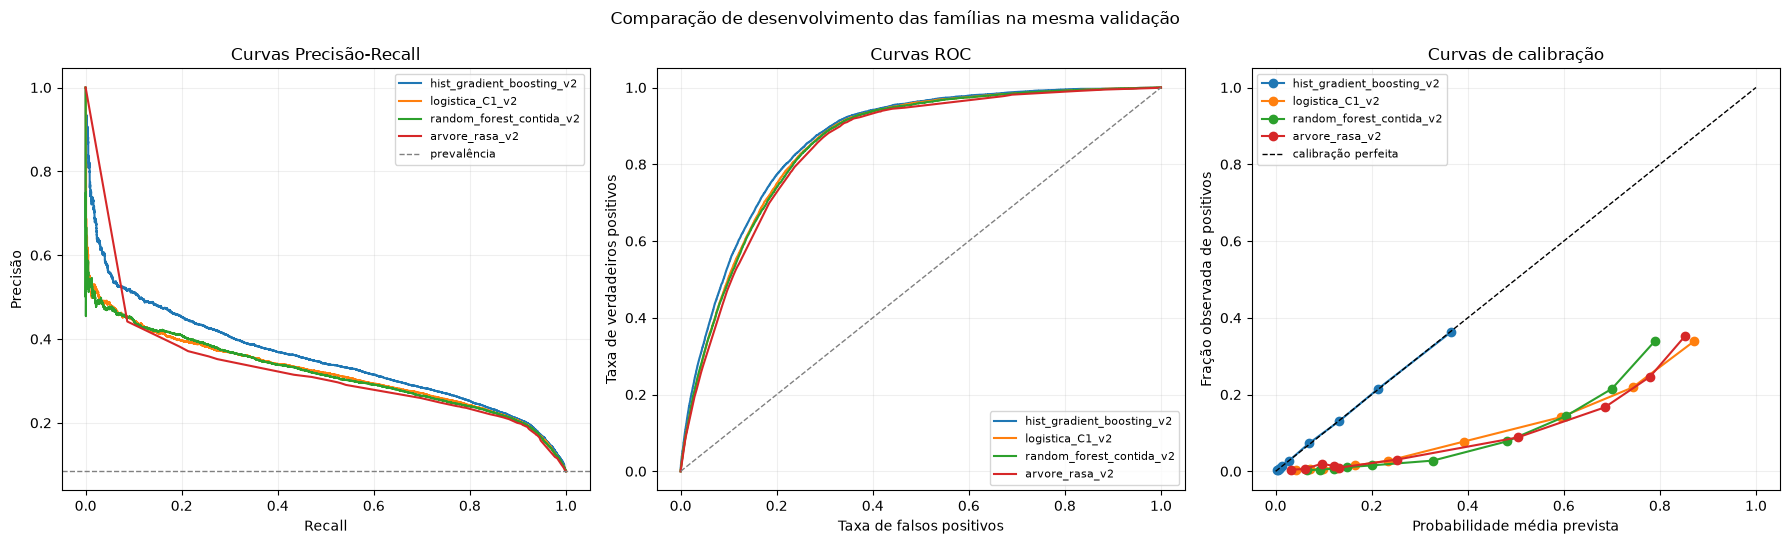

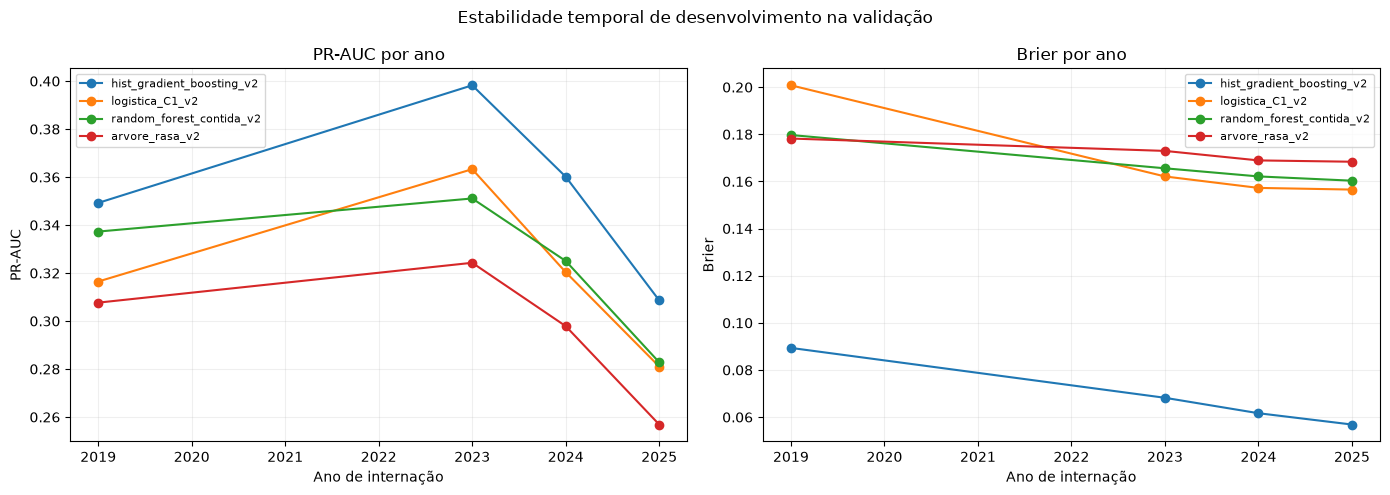

,modelo,ano_internacao,n,positivos,prevalencia,pr_auc,roc_auc,brier,probabilidade_media
0,arvore_rasa_v2,2019,6509,781,0.119988,0.307675,0.794508,0.178201,0.356688
1,arvore_rasa_v2,2023,35697,3372,0.094462,0.324284,0.852741,0.172952,0.346039
2,arvore_rasa_v2,2024,34012,2794,0.082147,0.297877,0.848147,0.168920,0.333493
3,arvore_rasa_v2,2025,43025,3117,0.072446,0.256872,0.846173,0.168361,0.328131
4,dummy_prior_v2,2019,6509,781,0.119988,0.119988,0.500000,0.106858,0.084390
5,dummy_prior_v2,2023,35697,3372,0.094462,0.094462,0.500000,0.085640,0.084390
6,dummy_prior_v2,2024,34012,2794,0.082147,0.082147,0.500000,0.075404,0.084390
7,dummy_prior_v2,2025,43025,3117,0.072446,0.072446,0.500000,0.067340,0.084390
8,hist_gradient_boosting_v2,2019,6509,781,0.119988,0.349241,0.814227,0.089362,0.108907
9,hist_gradient_boosting_v2,2023,35697,3372,0.094462,0.398258,0.871376,0.068200,0.087795


,modelo,pr_auc_min,pr_auc_max,pr_auc_media,roc_auc_min,roc_auc_max,brier_min,brier_max,amplitude_pr_auc,amplitude_roc_auc
0,arvore_rasa_v2,0.256872,0.324284,0.296677,0.794508,0.852741,0.168361,0.178201,0.067412,0.058233
1,random_forest_contida_v2,0.282789,0.351094,0.324055,0.805626,0.859161,0.160317,0.179697,0.068305,0.053536
2,logistica_C1_v2,0.281031,0.363297,0.320293,0.798388,0.862112,0.156544,0.200791,0.082267,0.063724
3,hist_gradient_boosting_v2,0.308611,0.398258,0.354063,0.814227,0.871376,0.056852,0.089362,0.089647,0.057148


Figuras gravadas:
- C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\supervisionado_05\05_pilotos_curvas_pr_roc_calibracao.png
- C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\reports\figures\supervisionado_05\05_pilotos_metricas_por_ano.png


In [21]:

import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_curve


FIGURES_DIR = ROOT_DIR / "reports" / "figures" / "supervisionado_05"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

modelos_avaliaveis = (
    resultados_cinco_familias.loc[
        resultados_cinco_familias["modelo"].ne("dummy_prior_v2"),
        "modelo",
    ]
    .tolist()
)

figura_curvas, eixos_curvas = plt.subplots(
    1,
    3,
    figsize=(18, 5.5),
)

prevalencia_validacao_piloto = float(
    y_validacao_piloto.mean()
)

for modelo in modelos_avaliaveis:
    dados_modelo = predicoes_cinco_familias_df.loc[
        predicoes_cinco_familias_df["modelo"].eq(modelo)
    ]

    precisao, recall, _ = precision_recall_curve(
        dados_modelo["y_true"],
        dados_modelo["y_prob"],
    )

    falso_positivo, verdadeiro_positivo, _ = roc_curve(
        dados_modelo["y_true"],
        dados_modelo["y_prob"],
    )

    fracao_positivos, media_prevista = calibration_curve(
        dados_modelo["y_true"],
        dados_modelo["y_prob"],
        n_bins=10,
        strategy="quantile",
    )

    eixos_curvas[0].plot(
        recall,
        precisao,
        label=modelo,
    )

    eixos_curvas[1].plot(
        falso_positivo,
        verdadeiro_positivo,
        label=modelo,
    )

    eixos_curvas[2].plot(
        media_prevista,
        fracao_positivos,
        marker="o",
        label=modelo,
    )


eixos_curvas[0].axhline(
    prevalencia_validacao_piloto,
    linestyle="--",
    color="gray",
    linewidth=1,
    label="prevalência",
)
eixos_curvas[0].set_title("Curvas Precisão-Recall")
eixos_curvas[0].set_xlabel("Recall")
eixos_curvas[0].set_ylabel("Precisão")

eixos_curvas[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1,
)
eixos_curvas[1].set_title("Curvas ROC")
eixos_curvas[1].set_xlabel("Taxa de falsos positivos")
eixos_curvas[1].set_ylabel("Taxa de verdadeiros positivos")

eixos_curvas[2].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    linewidth=1,
    label="calibração perfeita",
)
eixos_curvas[2].set_title("Curvas de calibração")
eixos_curvas[2].set_xlabel("Probabilidade média prevista")
eixos_curvas[2].set_ylabel("Fração observada de positivos")

for eixo in eixos_curvas:
    eixo.grid(alpha=0.2)
    eixo.legend(fontsize=8)

figura_curvas.suptitle(
    "Comparação de desenvolvimento das famílias na mesma validação"
)
figura_curvas.tight_layout()

caminho_figura_curvas = (
    FIGURES_DIR
    / "05_pilotos_curvas_pr_roc_calibracao.png"
)
figura_curvas.savefig(
    caminho_figura_curvas,
    dpi=160,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
plt.close(figura_curvas)


metricas_por_ano = []

pares_modelo_ano = (
    predicoes_cinco_familias_df[
        ["modelo", "ano_internacao"]
    ]
    .dropna()
    .drop_duplicates()
    .to_dict(orient="records")
)

for par in pares_modelo_ano:
    modelo = par["modelo"]
    ano = par["ano_internacao"]

    grupo = predicoes_cinco_familias_df.loc[
        predicoes_cinco_familias_df["modelo"].eq(modelo)
        & predicoes_cinco_familias_df["ano_internacao"].eq(ano)
    ]

    if grupo.empty:
        continue

    y_ano = grupo["y_true"].to_numpy(dtype=np.int8)
    prob_ano = grupo["y_prob"].to_numpy(dtype=float)

    if np.unique(y_ano).size < 2:
        roc_auc_ano = np.nan
        pr_auc_ano = np.nan
    else:
        roc_auc_ano = float(roc_auc_score(y_ano, prob_ano))
        pr_auc_ano = float(average_precision_score(y_ano, prob_ano))

    metricas_por_ano.append(
        {
            "modelo": modelo,
            "ano_internacao": int(ano),
            "n": int(len(grupo)),
            "positivos": int(y_ano.sum()),
            "prevalencia": float(y_ano.mean()),
            "pr_auc": pr_auc_ano,
            "roc_auc": roc_auc_ano,
            "brier": float(brier_score_loss(y_ano, prob_ano)),
            "probabilidade_media": float(prob_ano.mean()),
        }
    )

metricas_por_ano_df = pd.DataFrame(
    metricas_por_ano
)

variacao_temporal_modelos = (
    metricas_por_ano_df.loc[
        metricas_por_ano_df["modelo"].ne("dummy_prior_v2")
    ]
    .groupby("modelo", observed=True)
    .agg(
        pr_auc_min=("pr_auc", "min"),
        pr_auc_max=("pr_auc", "max"),
        pr_auc_media=("pr_auc", "mean"),
        roc_auc_min=("roc_auc", "min"),
        roc_auc_max=("roc_auc", "max"),
        brier_min=("brier", "min"),
        brier_max=("brier", "max"),
    )
    .reset_index()
)

variacao_temporal_modelos["amplitude_pr_auc"] = (
    variacao_temporal_modelos["pr_auc_max"]
    - variacao_temporal_modelos["pr_auc_min"]
)

variacao_temporal_modelos["amplitude_roc_auc"] = (
    variacao_temporal_modelos["roc_auc_max"]
    - variacao_temporal_modelos["roc_auc_min"]
)

figura_temporal, eixos_temporais = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

for modelo in modelos_avaliaveis:
    dados_modelo = metricas_por_ano_df.loc[
        metricas_por_ano_df["modelo"].eq(modelo)
    ].sort_values("ano_internacao")

    eixos_temporais[0].plot(
        dados_modelo["ano_internacao"],
        dados_modelo["pr_auc"],
        marker="o",
        label=modelo,
    )

    eixos_temporais[1].plot(
        dados_modelo["ano_internacao"],
        dados_modelo["brier"],
        marker="o",
        label=modelo,
    )


eixos_temporais[0].set_title("PR-AUC por ano")
eixos_temporais[0].set_xlabel("Ano de internação")
eixos_temporais[0].set_ylabel("PR-AUC")

eixos_temporais[1].set_title("Brier por ano")
eixos_temporais[1].set_xlabel("Ano de internação")
eixos_temporais[1].set_ylabel("Brier")

for eixo in eixos_temporais:
    eixo.grid(alpha=0.2)
    eixo.legend(fontsize=8)

figura_temporal.suptitle(
    "Estabilidade temporal de desenvolvimento na validação"
)
figura_temporal.tight_layout()

caminho_figura_temporal = (
    FIGURES_DIR
    / "05_pilotos_metricas_por_ano.png"
)
figura_temporal.savefig(
    caminho_figura_temporal,
    dpi=160,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
plt.close(figura_temporal)


display(
    metricas_por_ano_df.sort_values(
        ["modelo", "ano_internacao"]
    ).reset_index(drop=True)
)

display(
    variacao_temporal_modelos.sort_values(
        ["amplitude_pr_auc", "pr_auc_media"],
        ascending=[True, False],
    ).reset_index(drop=True)
)

print("Figuras gravadas:")
print("-", caminho_figura_curvas)
print("-", caminho_figura_temporal)

In [22]:

import json


timestamp_comparacao = pd.Timestamp.now(
    tz="UTC"
).strftime("%Y%m%dT%H%M%SZ")

prefixo_comparacao = (
    f"05_cinco_familias_{STATUS_COORTE}"
)

caminho_resultados_cinco = (
    Path(TABLES_DIR)
    / f"{prefixo_comparacao}_metricas.csv"
)

caminho_metricas_ano = (
    Path(TABLES_DIR)
    / f"{prefixo_comparacao}_metricas_por_ano.csv"
)

caminho_variacao_temporal = (
    Path(TABLES_DIR)
    / f"{prefixo_comparacao}_variacao_temporal.csv"
)

caminho_amostras = (
    Path(TABLES_DIR)
    / f"{prefixo_comparacao}_amostras.csv"
)

caminho_predicoes_cinco = (
    Path(PREDICTIONS_DIR)
    / f"{prefixo_comparacao}_predicoes_validacao.parquet"
)

caminho_manifesto_cinco = (
    Path(TABLES_DIR)
    / f"{prefixo_comparacao}_manifesto.json"
)

resultados_cinco_familias.to_csv(
    caminho_resultados_cinco,
    index=False,
    encoding="utf-8-sig",
)

metricas_por_ano_df.to_csv(
    caminho_metricas_ano,
    index=False,
    encoding="utf-8-sig",
)

variacao_temporal_modelos.to_csv(
    caminho_variacao_temporal,
    index=False,
    encoding="utf-8-sig",
)

resumo_amostras_comparacao.to_csv(
    caminho_amostras,
    index=False,
    encoding="utf-8-sig",
)

predicoes_cinco_familias_df.to_parquet(
    caminho_predicoes_cinco,
    index=False,
)

COLUNA_PROB_POR_MODELO = {
    "dummy_prior_v2": "prob_dummy",
    "logistica_C1_v2": "prob_logistica",
    "arvore_rasa_v2": "prob_arvore",
    "random_forest_contida_v2": "prob_random_forest",
    "hist_gradient_boosting_v2": "prob_boosting",
}
probabilidades_largas = (
    predicoes_cinco_familias_df.pivot(index="id_registro", columns="modelo", values="y_prob")
    .rename(columns=COLUNA_PROB_POR_MODELO)
    .astype("float32")
    .reset_index()
)
probabilidades_largas.columns.name = None

COLUNAS_FASE_E = [
    coluna
    for coluna in ["id_registro", COLUNA_PARTICAO, COLUNA_ANO, "regiao_residencia", "sg_uf", "faixa_etaria", "sexo_categoria"]
    if coluna in validacao.columns
]
identificacao_fase_e = validacao.loc[X_validacao_piloto.index, COLUNAS_FASE_E].copy()
identificacao_fase_e = identificacao_fase_e.rename(columns={COLUNA_PARTICAO: "bloco_mestre"})
identificacao_fase_e["bloco_mestre"] = identificacao_fase_e["bloco_mestre"].astype("string")
identificacao_fase_e["y"] = y_validacao_piloto.to_numpy()

predicoes_validacao_piloto = identificacao_fase_e.merge(
    probabilidades_largas, on="id_registro", how="left", validate="one_to_one"
).reset_index(drop=True)
predicoes_val_ref_piloto = predicoes_validacao_piloto.loc[
    predicoes_validacao_piloto["bloco_mestre"].eq("val_ref")
].reset_index(drop=True)

FINAL_DIR = ROOT_DIR / "outputs" / "final"
FINAL_DIR.mkdir(parents=True, exist_ok=True)
caminho_predicoes_val_ref = FINAL_DIR / "predicoes_val_ref_piloto.parquet"
caminho_predicoes_validacao_piloto = FINAL_DIR / "predicoes_validacao_piloto.parquet"
predicoes_val_ref_piloto.to_parquet(caminho_predicoes_val_ref, index=False)
predicoes_validacao_piloto.to_parquet(caminho_predicoes_validacao_piloto, index=False)


ranking_desenvolvimento = (
    resultados_cinco_familias.loc[
        resultados_cinco_familias["modelo"].ne("dummy_prior_v2")
    ]
    .copy()
    .sort_values(
        ["pr_auc", "brier", "duracao_fit_s"],
        ascending=[False, True, True],
    )
    .reset_index(drop=True)
)

shortlist_desenvolvimento = ranking_desenvolvimento.head(2)[
    "modelo"
].tolist()

manifesto_cinco = {
    "status_coorte": STATUS_COORTE,
    "versao_execucao": VERSAO_COMPARACAO,
    "carater": (
        "comparacao_definitiva_de_integracao"
        if TIPO_COORTE == "final"
        else "comparacao_de_desenvolvimento"
    ),
    "seed": int(SEED),
    "n_treino_piloto": int(len(X_treino_piloto)),
    "n_validacao_piloto": int(len(X_validacao_piloto)),
    "features": list(FEATURES_PILOTO),
    "modelos": list(modelos_piloto.keys()),
    "shortlist_desenvolvimento": shortlist_desenvolvimento,
    "teste_aberto": False,
    "limiar_selecionado": False,
    "calibracao_aplicada": False,
    "tuning_realizado": False,
    "observacoes": [
        (
            "Resultados produzidos com a coorte definitiva publicada."
            if TIPO_COORTE == "final"
            else "Resultados dependem da coorte de desenvolvimento."
        ),
        "Amostras comparáveis foram usadas para controlar custo.",
        "A shortlist não congela finalistas.",
        "O teste permaneceu fechado.",
        "Calibração e limiar pertencem à próxima etapa.",
    ],
    "artefatos": {
        "metricas": str(caminho_resultados_cinco),
        "metricas_por_ano": str(caminho_metricas_ano),
        "variacao_temporal": str(caminho_variacao_temporal),
        "amostras": str(caminho_amostras),
        "predicoes_validacao": str(caminho_predicoes_cinco),
        "figura_curvas": str(caminho_figura_curvas),
        "figura_temporal": str(caminho_figura_temporal),
        "predicoes_val_ref_fase_e": str(caminho_predicoes_val_ref),
        "predicoes_validacao_fase_e": str(caminho_predicoes_validacao_piloto),
    },
    "validacao_completa": bool(VALIDACAO_COMPLETA_NA_COMPARACAO),
    "dataset_sha256": manifest.get("dataset_sha256"),
    "particao_mestre_sha256": manifesto_mestre.get("partition_sha256"),
}

caminho_manifesto_cinco.write_text(
    json.dumps(
        manifesto_cinco,
        indent=2,
        ensure_ascii=False,
        default=str,
    ),
    encoding="utf-8",
)


resultados_reabertos = pd.read_csv(
    caminho_resultados_cinco,
    encoding="utf-8-sig",
)

predicoes_reabertas = pd.read_parquet(
    caminho_predicoes_cinco
)

manifesto_reaberto_cinco = json.loads(
    caminho_manifesto_cinco.read_text(
        encoding="utf-8"
    )
)

validacoes_comparacao = {
    "cinco_modelos_registrados": len(resultados_reabertos) == 5,
    "cinco_modelos_com_predicoes": predicoes_reabertas["modelo"].nunique() == 5,
    "probabilidades_validas": predicoes_reabertas["y_prob"].between(0, 1).all(),
    "teste_permaneceu_fechado": manifesto_reaberto_cinco["teste_aberto"] is False,
    "status_coorte_confere": (
        manifesto_reaberto_cinco["status_coorte"]
        == STATUS_COORTE
    ),
    "sem_tuning": manifesto_reaberto_cinco["tuning_realizado"] is False,
    "sem_limiar_final": manifesto_reaberto_cinco["limiar_selecionado"] is False,
    "figuras_existentes": caminho_figura_curvas.exists() and caminho_figura_temporal.exists(),
    "val_ref_fase_e_existe": caminho_predicoes_val_ref.exists(),
    "val_ref_fase_e_colunas": {
        "id_registro", "bloco_mestre", COLUNA_ANO, "regiao_residencia", "sg_uf",
        "faixa_etaria", "sexo_categoria", "y", "prob_logistica", "prob_boosting",
    } <= set(pd.read_parquet(caminho_predicoes_val_ref).columns),
    "val_ref_fase_e_so_val_ref": set(
        pd.read_parquet(caminho_predicoes_val_ref, columns=["bloco_mestre"])["bloco_mestre"].astype(str)
    ) == {"val_ref"},
    "val_ref_fase_e_completo": (
        len(predicoes_val_ref_piloto) == int((validacao[COLUNA_PARTICAO].astype(str) == "val_ref").sum())
    ),
    "val_ref_fase_e_sem_prob_vazia": bool(
        predicoes_val_ref_piloto[list(COLUNA_PROB_POR_MODELO.values())].notna().all().all()
    ),
}

validacoes_comparacao_df = pd.DataFrame(
    {
        "verificacao": validacoes_comparacao.keys(),
        "resultado": validacoes_comparacao.values(),
    }
)

display(validacoes_comparacao_df)

if not all(validacoes_comparacao.values()):
    falhas = [
        chave
        for chave, valor in validacoes_comparacao.items()
        if not valor
    ]
    raise RuntimeError(
        "Falhas na comparação da coorte: "
        f"{falhas}"
    )

print("Shortlist de desenvolvimento, sem congelamento:", shortlist_desenvolvimento)
print("Artefatos da comparação gravados com sucesso.")
print("Previsões:", caminho_predicoes_val_ref, f"({len(predicoes_val_ref_piloto):,} linhas)")
print("O teste permaneceu fechado.")
print(
    "Próximo gate: confirmar os finalistas na coorte definitiva "
    "antes do tuning limitado, da calibração e do limiar."
)

,verificacao,resultado
0,cinco_modelos_registrados,True
1,cinco_modelos_com_predicoes,True
2,probabilidades_validas,True
3,teste_permaneceu_fechado,True
4,status_coorte_confere,True
5,sem_tuning,True
6,sem_limiar_final,True
7,figuras_existentes,True
8,val_ref_fase_e_existe,True
9,val_ref_fase_e_colunas,True


Shortlist de desenvolvimento, sem congelamento: ['hist_gradient_boosting_v2', 'logistica_C1_v2']
Artefatos da comparação gravados com sucesso.
Previsões: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\final\predicoes_val_ref_piloto.parquet (119,243 linhas)
O teste permaneceu fechado.
Próximo gate: confirmar os finalistas na coorte definitiva antes do tuning limitado, da calibração e do limiar.


In [23]:
from sklearn.metrics import average_precision_score, roc_auc_score

from src.avaliacao import metricas_por_grupo

CAMPOS_SINTOMAS = ["febre", "tosse", "garganta", "dispneia", "diarreia", "vomito", "dor_abd", "fadiga", "perd_olft", "perd_pala", "outro_sin"]
CAMPOS_COMORBIDADES = [
    "puerpera", "cardiopati", "hematologi", "sind_down", "hepatica", "asma", "diabetes",
    "neurologic", "pneumopati", "imunodepre", "renal", "obesidade", "out_morbi",
]
CAMPOS_SINTOMAS_SECUNDARIOS = ["diarreia", "vomito", "garganta", "perd_olft", "perd_pala", "dor_abd", "fadiga"]
CAMPOS_PREENCHIMENTO = CAMPOS_SINTOMAS + CAMPOS_COMORBIDADES
LIMITE_SINTOMAS_EM_BRANCO = 6
MODELOS_PREENCHIMENTO = {"logistica": "prob_logistica", "boosting": "prob_boosting"}
FAIXAS_AMPLAS = {
    "<1": "menos de 5 anos", "1-4": "menos de 5 anos", "5-11": "5 a 17 anos", "12-17": "5 a 17 anos",
    "18-39": "18 a 59 anos", "40-59": "18 a 59 anos", "60-79": "60 anos ou mais", "80+": "60 anos ou mais",
}
ORDEM_FAIXAS_AMPLAS = ["menos de 5 anos", "5 a 17 anos", "18 a 59 anos", "60 anos ou mais"]
ORDEM_PADROES = ["comorbidades_sem_nao", "sim_e_nao", "sintomas_em_branco"]
PADRAO_DE_REFERENCIA = "comorbidades_sem_nao"
MINIMO_FICHAS_ESTRATO = 100
MINIMO_POR_CLASSE = 30
REPETICOES_BOOTSTRAP = 500
NOMES_METRICAS = ["roc_auc", "pr_auc", "pr_auc_sobre_prevalencia", "brier", "o_e"]
PASTA_SAIDA_PREENCHIMENTO = ROOT_DIR / "outputs" / "final"


def derivar_preenchimento(dados: pd.DataFrame) -> pd.DataFrame:
    """Acrescenta completude, padrão de preenchimento, terço de completude e faixa etária ampla."""
    texto = {c: dados[c].astype("string").str.strip().replace("", pd.NA) for c in CAMPOS_PREENCHIMENTO}
    respondida = pd.DataFrame({c: texto[c].isin(["1", "2"]) for c in CAMPOS_PREENCHIMENTO})
    em_branco = pd.DataFrame({c: texto[c].isna() for c in CAMPOS_PREENCHIMENTO})
    com_nao = pd.DataFrame({c: texto[c].eq("2").fillna(False).astype(bool) for c in CAMPOS_COMORBIDADES}).any(axis=1)

    saida = dados.copy()
    saida["completude_pct"] = 100 * respondida.sum(axis=1) / len(CAMPOS_PREENCHIMENTO)
    saida["alguma_comorbidade_respondida"] = respondida[CAMPOS_COMORBIDADES].any(axis=1)
    saida["modo_de_registro"] = np.select(
        [em_branco[CAMPOS_SINTOMAS_SECUNDARIOS].sum(axis=1) >= LIMITE_SINTOMAS_EM_BRANCO, ~com_nao],
        ["sintomas_em_branco", "comorbidades_sem_nao"],
        default="sim_e_nao",
    )
    try:
        terco = pd.qcut(saida["completude_pct"], 3, duplicates="drop")
    except ValueError as erro_qcut:
        raise RuntimeError("A completude quase não varia entre as fichas; não dá para formar terços.") from erro_qcut
    if terco.cat.categories.size < 3:
        print(f"Aviso: a completude tem valores repetidos demais e gerou {terco.cat.categories.size} faixas em vez de 3.")
    rotulos = {intervalo: f"T{i + 1}" for i, intervalo in enumerate(terco.cat.categories)}
    saida["terco_completude"] = terco.map(rotulos).astype("string")
    saida["faixa_ampla"] = dados["faixa_etaria"].astype("string").map(FAIXAS_AMPLAS)
    return saida


def metricas_ponderadas(y: np.ndarray, p: np.ndarray, w: np.ndarray) -> np.ndarray:
    """ROC-AUC, PR-AUC, PR-AUC dividida pela prevalência, Brier e O/E com pesos por ficha."""
    usar = w > 0
    y, p, w = y[usar], p[usar], w[usar]
    positivos, negativos = w[y == 1].sum(), w[y == 0].sum()
    if positivos <= 0 or negativos <= 0:
        return np.full(5, np.nan)
    pr_auc = average_precision_score(y, p, sample_weight=w)
    return np.array([
        roc_auc_score(y, p, sample_weight=w), pr_auc, pr_auc / (positivos / (positivos + negativos)),
        np.average((y - p) ** 2, weights=w), positivos / float(np.sum(w * p)),
    ])


def pesos_por_grupo(codigos: np.ndarray, n_grupos: int, gerador: np.random.Generator) -> np.ndarray:
    """Peso de cada ficha: quantas vezes o seu grupo foi sorteado nesta réplica."""
    return np.bincount(gerador.integers(0, n_grupos, n_grupos), minlength=n_grupos)[codigos].astype(float)


def ic_por_grupo(y: np.ndarray, probas: dict[str, np.ndarray], grupos: np.ndarray, repeticoes: int, semente: int) -> dict[str, np.ndarray]:
    """Percentis 2,5 e 97,5 das cinco métricas de cada modelo, com as mesmas réplicas para todos."""
    codigos = pd.factorize(grupos)[0]
    n_grupos = int(codigos.max()) + 1
    gerador = np.random.default_rng(semente)
    replicas = {nome: np.full((repeticoes, 5), np.nan) for nome in probas}
    for i in range(repeticoes):
        pesos = pesos_por_grupo(codigos, n_grupos, gerador)
        for nome, p in probas.items():
            replicas[nome][i] = metricas_ponderadas(y, p, pesos)
    return {nome: np.nanpercentile(r, [2.5, 97.5], axis=0) for nome, r in replicas.items()}


def tabela_por_estrato(dados: pd.DataFrame, coluna: str, repeticoes: int, semente: int, ordem: list[str] | None = None) -> pd.DataFrame:
    """Métricas por estrato e modelo: estimativa de metricas_por_grupo (src) e intervalo por bootstrap de grupos."""
    base = dados.copy()
    base["todos"] = "todos"
    estratos = ["todos"] + (ordem if ordem is not None else sorted(base[coluna].dropna().astype(str).unique()))
    pontual = {}
    for nome_modelo, coluna_prob in MODELOS_PREENCHIMENTO.items():
        for coluna_grupo in (coluna, "todos"):
            metricas = metricas_por_grupo(base, base["y"], base[coluna_prob], coluna_grupo, min_n=MINIMO_FICHAS_ESTRATO)
            for _, linha in metricas.iterrows():
                if coluna_grupo == "todos" or linha["grupo"] != "todos":
                    pontual[(nome_modelo, str(linha["grupo"]))] = linha
    fonte_metrica = {"roc_auc": "roc_auc", "pr_auc": "pr_auc", "pr_auc_sobre_prevalencia": "pr_auc_sobre_prev", "brier": "brier", "o_e": "o_e"}
    linhas = []
    for estrato in estratos:
        sub = base[(base["todos"] == "todos") if estrato == "todos" else (base[coluna].astype("string") == estrato)]
        obitos, curas = int(sub["y"].sum()), int((1 - sub["y"]).sum())
        suprimido = len(sub) < MINIMO_FICHAS_ESTRATO or obitos < MINIMO_POR_CLASSE or curas < MINIMO_POR_CLASSE
        ics = None
        if not suprimido:
            ics = ic_por_grupo(
                sub["y"].to_numpy(), {m: sub[c].to_numpy(dtype=float) for m, c in MODELOS_PREENCHIMENTO.items()},
                sub["group_id"].to_numpy(), repeticoes, semente,
            )
        for nome_modelo in MODELOS_PREENCHIMENTO:
            linha = {
                "estrato": estrato, "modelo": nome_modelo, "n": len(sub), "obitos": obitos,
                "prevalencia": obitos / len(sub) if len(sub) else np.nan, "suprimido": suprimido,
            }
            ponto = pontual.get((nome_modelo, estrato))
            for k, metrica in enumerate(NOMES_METRICAS):
                linha[metrica] = np.nan if suprimido or ponto is None else float(ponto[fonte_metrica[metrica]])
                linha[f"{metrica}_ic_inf"] = np.nan if ics is None else float(ics[nome_modelo][0, k])
                linha[f"{metrica}_ic_sup"] = np.nan if ics is None else float(ics[nome_modelo][1, k])
            linhas.append(linha)
    resultado = pd.DataFrame(linhas)
    total = resultado[resultado["estrato"] == "todos"].set_index("modelo")["o_e"]
    resultado["o_e_relativo_ao_total"] = resultado["o_e"] / resultado["modelo"].map(total)
    resultado["repeticoes_bootstrap"] = repeticoes
    resultado["semente"] = semente
    return resultado


def tabela_modo_por_faixa(dados: pd.DataFrame, repeticoes: int, semente: int) -> pd.DataFrame:
    base = dados.dropna(subset=["faixa_ampla"]).copy()
    base["modo_e_faixa"] = base["modo_de_registro"].astype(str) + "|" + base["faixa_ampla"].astype(str)
    ordem = [f"{m}|{f}" for f in ORDEM_FAIXAS_AMPLAS for m in ORDEM_PADROES]
    resultado = tabela_por_estrato(base, "modo_e_faixa", repeticoes, semente, ordem=[o for o in ordem if o in set(base["modo_e_faixa"])])
    partes = resultado["estrato"].str.split("|", expand=True)
    resultado.insert(1, "faixa_etaria_ampla", partes[1].where(resultado["estrato"] != "todos", "todas"))
    resultado.insert(1, "modo_de_registro", partes[0].where(resultado["estrato"] != "todos", "todos"))
    return resultado.drop(columns="estrato")


def tabela_padronizacao_por_idade(dados: pd.DataFrame) -> pd.DataFrame:
    """Mortalidade de cada padrão contra a esperada se tivesse a mortalidade por faixa etária do padrão de referência."""
    base = dados.dropna(subset=["faixa_ampla"])
    por_faixa = base.groupby(["modo_de_registro", "faixa_ampla"], observed=True)["y"].agg(["size", "sum"])
    referencia = por_faixa.loc[PADRAO_DE_REFERENCIA]
    mortalidade_referencia = referencia["sum"] / referencia["size"]
    mortalidade_bruta_referencia = float(referencia["sum"].sum() / referencia["size"].sum())
    linhas = []
    for padrao in ORDEM_PADROES:
        faixas = por_faixa.loc[padrao]
        fichas, obitos = int(faixas["size"].sum()), int(faixas["sum"].sum())
        esperados = float((faixas["size"] * mortalidade_referencia.reindex(faixas.index)).sum())
        linhas.append({
            "modo_de_registro": padrao,
            "fichas": fichas,
            "pct_60_anos_ou_mais": 100 * float(faixas["size"].get("60 anos ou mais", 0)) / fichas,
            "obitos": obitos,
            "mortalidade_pct": 100 * obitos / fichas,
            "razao_bruta_contra_referencia": (obitos / fichas) / mortalidade_bruta_referencia,
            "obitos_esperados_pela_idade": esperados,
            "razao_padronizada_por_idade": obitos / esperados,
        })
    return pd.DataFrame(linhas)


def diferenca_por_grupo(x: np.ndarray, y: np.ndarray, grupos: np.ndarray, repeticoes: int, semente: int) -> np.ndarray:
    """Percentis 2,5 e 97,5 da média de x nos óbitos menos a média nos não óbitos, sorteando grupos com reposição."""
    codigos = pd.factorize(grupos)[0]
    n_grupos = int(codigos.max()) + 1
    gerador = np.random.default_rng(semente)
    valores = np.full(repeticoes, np.nan)
    for i in range(repeticoes):
        pesos = pesos_por_grupo(codigos, n_grupos, gerador)
        obito, cura = pesos * (y == 1), pesos * (y == 0)
        if obito.sum() > 0 and cura.sum() > 0:
            valores[i] = np.sum(obito * x) / obito.sum() - np.sum(cura * x) / cura.sum()
    return np.nanpercentile(valores, [2.5, 97.5])


def tabela_preenchimento_por_desfecho(dados: pd.DataFrame, repeticoes: int, semente: int) -> pd.DataFrame:
    linhas = []
    for faixa in ["todas", *ORDEM_FAIXAS_AMPLAS]:
        sub = dados if faixa == "todas" else dados[dados["faixa_ampla"] == faixa]
        obitos, curas = int(sub["y"].sum()), int((1 - sub["y"]).sum())
        for indicador, rotulo in (
            ("alguma_comorbidade_respondida", "% com alguma comorbidade respondida"),
            ("completude_pct", "completude média (% dos 24 campos)"),
        ):
            x = sub[indicador].to_numpy(dtype=float) * (100.0 if indicador == "alguma_comorbidade_respondida" else 1.0)
            suprimido = obitos < MINIMO_POR_CLASSE or curas < MINIMO_POR_CLASSE
            linha = {"faixa_etaria_ampla": faixa, "indicador": rotulo, "n_obitos": obitos, "n_nao_obitos": curas, "suprimido": suprimido}
            if suprimido:
                linha.update({"obitos": np.nan, "nao_obitos": np.nan, "diferenca_obitos_menos_nao_obitos": np.nan, "ic_inf": np.nan, "ic_sup": np.nan})
            else:
                ic = diferenca_por_grupo(x, sub["y"].to_numpy(), sub["group_id"].to_numpy(), repeticoes, semente)
                media_obitos, media_curas = float(x[sub["y"].to_numpy() == 1].mean()), float(x[sub["y"].to_numpy() == 0].mean())
                linha.update({
                    "obitos": media_obitos, "nao_obitos": media_curas, "diferenca_obitos_menos_nao_obitos": media_obitos - media_curas,
                    "ic_inf": float(ic[0]), "ic_sup": float(ic[1]),
                })
            linhas.append(linha)
    resultado = pd.DataFrame(linhas)
    resultado["repeticoes_bootstrap"] = repeticoes
    resultado["semente"] = semente
    return resultado

In [24]:
objetos_preenchimento_necessarios = ["predicoes_val_ref_piloto", "validacao", "ALVO_MODELO", "COLUNA_PARTICAO", "SEED", "ROOT_DIR"]
objetos_preenchimento_ausentes = [nome for nome in objetos_preenchimento_necessarios if nome not in globals()]
if objetos_preenchimento_ausentes:
    raise NameError(
        "Execute primeiro as seções anteriores. Objetos ausentes: " + ", ".join(objetos_preenchimento_ausentes)
    )

inicio_preenchimento = time.perf_counter()

colunas_ficha_preenchimento = ["id_registro", "group_id", COLUNA_PARTICAO, ALVO_MODELO, *CAMPOS_PREENCHIMENTO]
base_preenchimento = predicoes_val_ref_piloto.merge(
    validacao[colunas_ficha_preenchimento], on="id_registro", how="left", validate="one_to_one"
)

colunas_previsao_exigidas = ["id_registro", "bloco_mestre", "faixa_etaria", "y", *MODELOS_PREENCHIMENTO.values()]
colunas_previsao_ausentes = [c for c in colunas_previsao_exigidas if c not in base_preenchimento.columns]
if colunas_previsao_ausentes:
    raise KeyError(f"As previsões não têm as colunas {colunas_previsao_ausentes}.")
if not base_preenchimento["bloco_mestre"].astype("string").eq("val_ref").all():
    raise RuntimeError("As previsões têm fichas de outro bloco além do val_ref.")
if not base_preenchimento[COLUNA_PARTICAO].astype("string").eq("val_ref").all():
    raise RuntimeError("O artefato coloca fichas das previsões fora do val_ref.")
if not base_preenchimento["id_registro"].is_unique:
    raise RuntimeError("As previsões têm id_registro repetido.")
if not set(base_preenchimento["y"].unique()) <= {0, 1}:
    raise RuntimeError("A coluna y das previsões não é binária.")
if base_preenchimento["group_id"].isna().any():
    raise RuntimeError("Há fichas das previsões sem group_id no artefato.")
if not (base_preenchimento["y"].to_numpy() == pd.to_numeric(base_preenchimento[ALVO_MODELO]).to_numpy()).all():
    raise RuntimeError("O desfecho das previsões difere do desfecho do artefato.")
for coluna_probabilidade in MODELOS_PREENCHIMENTO.values():
    if base_preenchimento[coluna_probabilidade].isna().any() or not base_preenchimento[coluna_probabilidade].between(0, 1).all():
        raise RuntimeError(f"A coluna {coluna_probabilidade} tem valor ausente ou fora de 0 a 1.")

dados_preenchimento = derivar_preenchimento(base_preenchimento)

print("Fichas do val_ref:", f"{len(dados_preenchimento):,}")
print("Óbitos:", f"{int(dados_preenchimento['y'].sum()):,}", f"({100 * dados_preenchimento['y'].mean():.2f}%)")
print("Grupos distintos (group_id):", f"{dados_preenchimento['group_id'].nunique():,}")
print("Fichas por padrão de preenchimento:", dados_preenchimento["modo_de_registro"].value_counts().to_dict())
print("Fichas por faixa etária ampla:", dados_preenchimento["faixa_ampla"].value_counts(dropna=False).to_dict())
print("Completude (% dos 24 campos respondidos) por terço:")
display(dados_preenchimento.groupby("terco_completude")["completude_pct"].agg(["min", "max", "size"]).round(1))
print("Tempo da preparação:", f"{time.perf_counter() - inicio_preenchimento:.1f} s")

Fichas do val_ref: 119,243
Óbitos: 10,064 (8.44%)
Grupos distintos (group_id): 119,243
Fichas por padrão de preenchimento: {'comorbidades_sem_nao': 58290, 'sim_e_nao': 35948, 'sintomas_em_branco': 25005}
Fichas por faixa etária ampla: {'menos de 5 anos': 55384, '60 anos ou mais': 32353, '18 a 59 anos': 16545, '5 a 17 anos': 14958, nan: 3}
Completude (% dos 24 campos respondidos) por terço:


,min,max,size
terco_completude,,,
T1,0.0,41.7,40856
T2,45.8,45.8,40095
T3,50.0,100.0,38292


Tempo da preparação: 1.4 s


In [25]:
inicio_preenchimento = time.perf_counter()

tabelas_preenchimento = {
    "completude_val_ref.csv": tabela_por_estrato(
        dados_preenchimento, "terco_completude", REPETICOES_BOOTSTRAP, SEED
    ),
    "modo_de_registro_val_ref.csv": tabela_por_estrato(
        dados_preenchimento, "modo_de_registro", REPETICOES_BOOTSTRAP, SEED, ordem=ORDEM_PADROES
    ),
    "modo_por_faixa_etaria_val_ref.csv": tabela_modo_por_faixa(dados_preenchimento, REPETICOES_BOOTSTRAP, SEED),
    "padronizacao_por_idade_val_ref.csv": tabela_padronizacao_por_idade(dados_preenchimento),
    "preenchimento_por_desfecho_val_ref.csv": tabela_preenchimento_por_desfecho(dados_preenchimento, REPETICOES_BOOTSTRAP, SEED),
}

PASTA_SAIDA_PREENCHIMENTO.mkdir(parents=True, exist_ok=True)
for nome_arquivo_preenchimento, tabela_para_gravar in tabelas_preenchimento.items():
    tabela_para_gravar.to_csv(PASTA_SAIDA_PREENCHIMENTO / nome_arquivo_preenchimento, index=False, encoding="utf-8-sig")

colunas_exibidas_estrato = [
    "estrato", "modelo", "n", "obitos", "prevalencia", "roc_auc", "roc_auc_ic_inf", "roc_auc_ic_sup",
    "pr_auc_sobre_prevalencia", "o_e_relativo_ao_total",
]
colunas_exibidas_faixa = [
    "modo_de_registro", "faixa_etaria_ampla", "modelo", "n", "obitos", "suprimido", "roc_auc", "roc_auc_ic_inf",
    "roc_auc_ic_sup", "o_e_relativo_ao_total",
]

print("Por terço de completude:")
display(tabelas_preenchimento["completude_val_ref.csv"][colunas_exibidas_estrato].round(3))
print("Por padrão de preenchimento:")
display(tabelas_preenchimento["modo_de_registro_val_ref.csv"][colunas_exibidas_estrato].round(3))
print("Por padrão de preenchimento dentro de cada faixa etária:")
display(tabelas_preenchimento["modo_por_faixa_etaria_val_ref.csv"][colunas_exibidas_faixa].round(3))
print("Mortalidade de cada padrão contra a esperada pela idade (referência: comorbidades_sem_nao):")
display(tabelas_preenchimento["padronizacao_por_idade_val_ref.csv"].round(3))
print("Preenchimento nas fichas de óbito contra as demais:")
display(tabelas_preenchimento["preenchimento_por_desfecho_val_ref.csv"].round(2))

for nome_arquivo_preenchimento in tabelas_preenchimento:
    print("Gravado:", PASTA_SAIDA_PREENCHIMENTO / nome_arquivo_preenchimento)
print("Tempo do bootstrap e da gravação:", f"{time.perf_counter() - inicio_preenchimento:.1f} s")

Por terço de completude:


,estrato,modelo,n,obitos,prevalencia,roc_auc,roc_auc_ic_inf,roc_auc_ic_sup,pr_auc_sobre_prevalencia,o_e_relativo_ao_total
0,todos,logistica,119243,10064,0.084,0.855,0.852,0.859,3.796,1.000
1,todos,boosting,119243,10064,0.084,0.865,0.862,0.868,4.203,1.000
2,T1,logistica,40856,2807,0.069,0.860,0.854,0.866,4.420,0.905
3,T1,boosting,40856,2807,0.069,0.872,0.866,0.879,5.205,0.988
4,T2,logistica,40095,1362,0.034,0.874,0.864,0.885,7.321,0.747
5,T2,boosting,40095,1362,0.034,0.884,0.875,0.894,8.592,1.018
6,T3,logistica,38292,5895,0.154,0.769,0.764,0.776,2.222,1.147
7,T3,boosting,38292,5895,0.154,0.781,0.775,0.786,2.361,1.002


Por padrão de preenchimento:


,estrato,modelo,n,obitos,prevalencia,roc_auc,roc_auc_ic_inf,roc_auc_ic_sup,pr_auc_sobre_prevalencia,o_e_relativo_ao_total
0,todos,logistica,119243,10064,0.084,0.855,0.852,0.859,3.796,1.000
1,todos,boosting,119243,10064,0.084,0.865,0.862,0.868,4.203,1.000
2,comorbidades_sem_nao,logistica,58290,2512,0.043,0.871,0.864,0.878,6.072,0.803
3,comorbidades_sem_nao,boosting,58290,2512,0.043,0.881,0.874,0.888,7.038,1.012
4,sim_e_nao,logistica,35948,5623,0.156,0.768,0.762,0.774,2.211,1.152
5,sim_e_nao,boosting,35948,5623,0.156,0.780,0.774,0.787,2.359,1.003
6,sintomas_em_branco,logistica,25005,1929,0.077,0.860,0.853,0.868,4.065,0.938
7,sintomas_em_branco,boosting,25005,1929,0.077,0.871,0.863,0.877,4.761,0.975


Por padrão de preenchimento dentro de cada faixa etária:


,modo_de_registro,faixa_etaria_ampla,modelo,n,obitos,suprimido,roc_auc,roc_auc_ic_inf,roc_auc_ic_sup,o_e_relativo_ao_total
0,todos,todas,logistica,119240,10064,False,0.855,0.852,0.859,1.000
1,todos,todas,boosting,119240,10064,False,0.865,0.862,0.868,1.000
2,comorbidades_sem_nao,menos de 5 anos,logistica,37224,388,False,0.697,0.671,0.721,0.346
3,comorbidades_sem_nao,menos de 5 anos,boosting,37224,388,False,0.719,0.693,0.744,1.019
4,sim_e_nao,menos de 5 anos,logistica,6684,196,False,0.749,0.719,0.779,0.564
5,sim_e_nao,menos de 5 anos,boosting,6684,196,False,0.774,0.746,0.804,1.005
6,sintomas_em_branco,menos de 5 anos,logistica,11476,93,False,0.669,0.607,0.726,0.267
7,sintomas_em_branco,menos de 5 anos,boosting,11476,93,False,0.711,0.657,0.760,0.831
8,comorbidades_sem_nao,5 a 17 anos,logistica,7714,91,False,0.735,0.684,0.784,0.341
9,comorbidades_sem_nao,5 a 17 anos,boosting,7714,91,False,0.775,0.725,0.826,1.033


Mortalidade de cada padrão contra a esperada pela idade (referência: comorbidades_sem_nao):


,modo_de_registro,fichas,pct_60_anos_ou_mais,obitos,mortalidade_pct,razao_bruta_contra_referencia,obitos_esperados_pela_idade,razao_padronizada_por_idade
0,comorbidades_sem_nao,58289,12.164,2512,4.310,1.00,2512.000,1.000
1,sim_e_nao,35948,50.598,5623,15.642,3.63,4414.915,1.274
2,sintomas_em_branco,25003,28.293,1929,7.715,1.79,1886.105,1.023


Preenchimento nas fichas de óbito contra as demais:


,faixa_etaria_ampla,indicador,n_obitos,n_nao_obitos,suprimido,obitos,nao_obitos,diferenca_obitos_menos_nao_obitos,ic_inf,ic_sup,repeticoes_bootstrap,semente
0,todas,% com alguma comorbidade respondida,10064,109179,False,75.31,39.18,36.13,35.30,37.04,500,42
1,todas,completude média (% dos 24 campos),10064,109179,False,66.94,51.47,15.47,14.72,16.18,500,42
2,menos de 5 anos,% com alguma comorbidade respondida,677,54707,False,38.85,17.29,21.56,17.85,25.14,500,42
3,menos de 5 anos,completude média (% dos 24 campos),677,54707,False,51.63,42.56,9.07,6.82,11.37,500,42
4,5 a 17 anos,% com alguma comorbidade respondida,231,14727,False,58.44,39.46,18.98,12.40,25.45,500,42
5,5 a 17 anos,completude média (% dos 24 campos),231,14727,False,59.51,51.44,8.07,3.48,12.55,500,42
6,18 a 59 anos,% com alguma comorbidade respondida,2118,14427,False,70.16,56.06,14.10,11.97,16.04,500,42
7,18 a 59 anos,completude média (% dos 24 campos),2118,14427,False,64.85,58.17,6.68,5.08,8.35,500,42
8,60 anos ou mais,% com alguma comorbidade respondida,7038,25315,False,80.92,76.70,4.22,3.16,5.23,500,42
9,60 anos ou mais,completude média (% dos 24 campos),7038,25315,False,69.28,66.92,2.36,1.38,3.38,500,42


Gravado: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\final\completude_val_ref.csv
Gravado: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\final\modo_de_registro_val_ref.csv
Gravado: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\final\modo_por_faixa_etaria_val_ref.csv
Gravado: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\final\padronizacao_por_idade_val_ref.csv
Gravado: C:\Users\ivanI\OneDrive\Documentos\Projetos\Projeto_Integrador\outputs\final\preenchimento_por_desfecho_val_ref.csv
Tempo do bootstrap e da gravação: 227.2 s
